# Applied Statistical Inference — Phase 1

Five executed case studies, with every result derived from the supplied CSV files. The reusable analysis is in `src/run_all.py`. Seed: `403109076`; bootstrap resamples: 3,000. These datasets illustrate methods and cannot establish causal or clinical effects.

## 0 | Run the complete pipeline

Validate input data, regenerate 14 publication-resolution figures, and save the machine-readable results used in the report.

In [1]:
from IPython.display import display, Image
import pandas as pd
from src.run_all import main, FIG
R = main()
print('Seed:', R['seed'], '| Figures:', len(list(FIG.glob('*.png'))))

Saved C:\Users\MEHR\Desktop\IT_PRJ_21776_GROUP_1\tmp\engineering-statistics-portfolio\phase1\reports\results.json and 14 figures
Seed: 403109076 | Figures: 14


## 1 | Sleep, activity, and stress

The sleep file contains 374 rows. The project brief describes it as synthetic; repeated profiles further limit generalization. `None` in the sleep-disorder column is a category, not missing data.

1. **Gender and stress:** H0: equal stress distributions; H1: different. Stress is ordinal, so use Mann–Whitney U, rank-biserial effect size, and a bootstrap interval for the median difference.
2. **Activity and steps:** H0: mean steps for activity ≥60 min/day ≤ mean steps for activity <40; H1: greater. Use a one-sided Welch test. Exclude the middle activity group by design.
3. **Sleep disorder and duration:** H0: equal mean hours for no disorder and any disorder; H1: different. Pool insomnia and apnea into any disorder, then use Welch.
4. **Men's stress and activity:** H0: mean activity at stress 3 ≤ mean activity at stress ≥7; H1: greater. Welch result is exploratory because the stress-3 subgroup is very small.

Shapiro and Levene diagnostics are reported. Welch targets means and large-group mean inference can remain useful when individual observations are nonnormal. Holm adjusts the four p-values for family-wise testing. Bootstrap 95% intervals estimate mean differences, except for ordinal stress, where they estimate a median difference.

In [2]:
M = R['module1']; T = M['tests']
print('Rows:', M['n'], '| Middle activity group excluded:', M['middle_activity_excluded'])
print('Disorder counts:', M['disorder_counts'])
display(pd.DataFrame([{'Question': k, 'Test': v['test'], 'n A':v['n_a'], 'n B':v['n_b'],
    'Statistic':v['statistic'], 'Raw p':v['p'], 'Holm p':v['holm_p'],
    'Effect':v['effect'], 'CI target':v['ci_target'], '95% CI':str([round(x,3) for x in v['ci']]),
    'Shapiro A':v['shapiro_a'], 'Shapiro B':v['shapiro_b'], 'Levene':v['levene']}
    for k,v in T.items()]).set_index('Question').round(4))

Rows: 374 | Middle activity group excluded: 87
Disorder counts: {'None': 219, 'Sleep Apnea': 78, 'Insomnia': 77}


,Test,n A,n B,Statistic,Raw p,Holm p,Effect,CI target,95% CI,Shapiro A,Shapiro B,Levene
Question,,,,,,,,,,,,
gender_stress,Mann-Whitney U,185,189,9034.0000,0.000,0.000,-0.4833,median difference,"[np.float64(-2.0), np.float64(-2.0)]",0.0000,0.0,0.0083
activity_steps,Welch t,213,74,17.8195,0.000,0.000,2.0372,mean difference,"[np.float64(2306.866), np.float64(2882.297)]",0.0000,0.0,0.0002
sleep_disorder,Welch t,219,155,6.8763,0.000,0.000,0.7286,mean difference,"[np.float64(0.383), np.float64(0.697)]",0.0000,0.0,0.9310
male_stress_activity,Welch t,4,74,2.3187,0.051,0.051,2.9124,mean difference,"[np.float64(6.905), np.float64(47.014)]",0.0239,0.0,0.0000


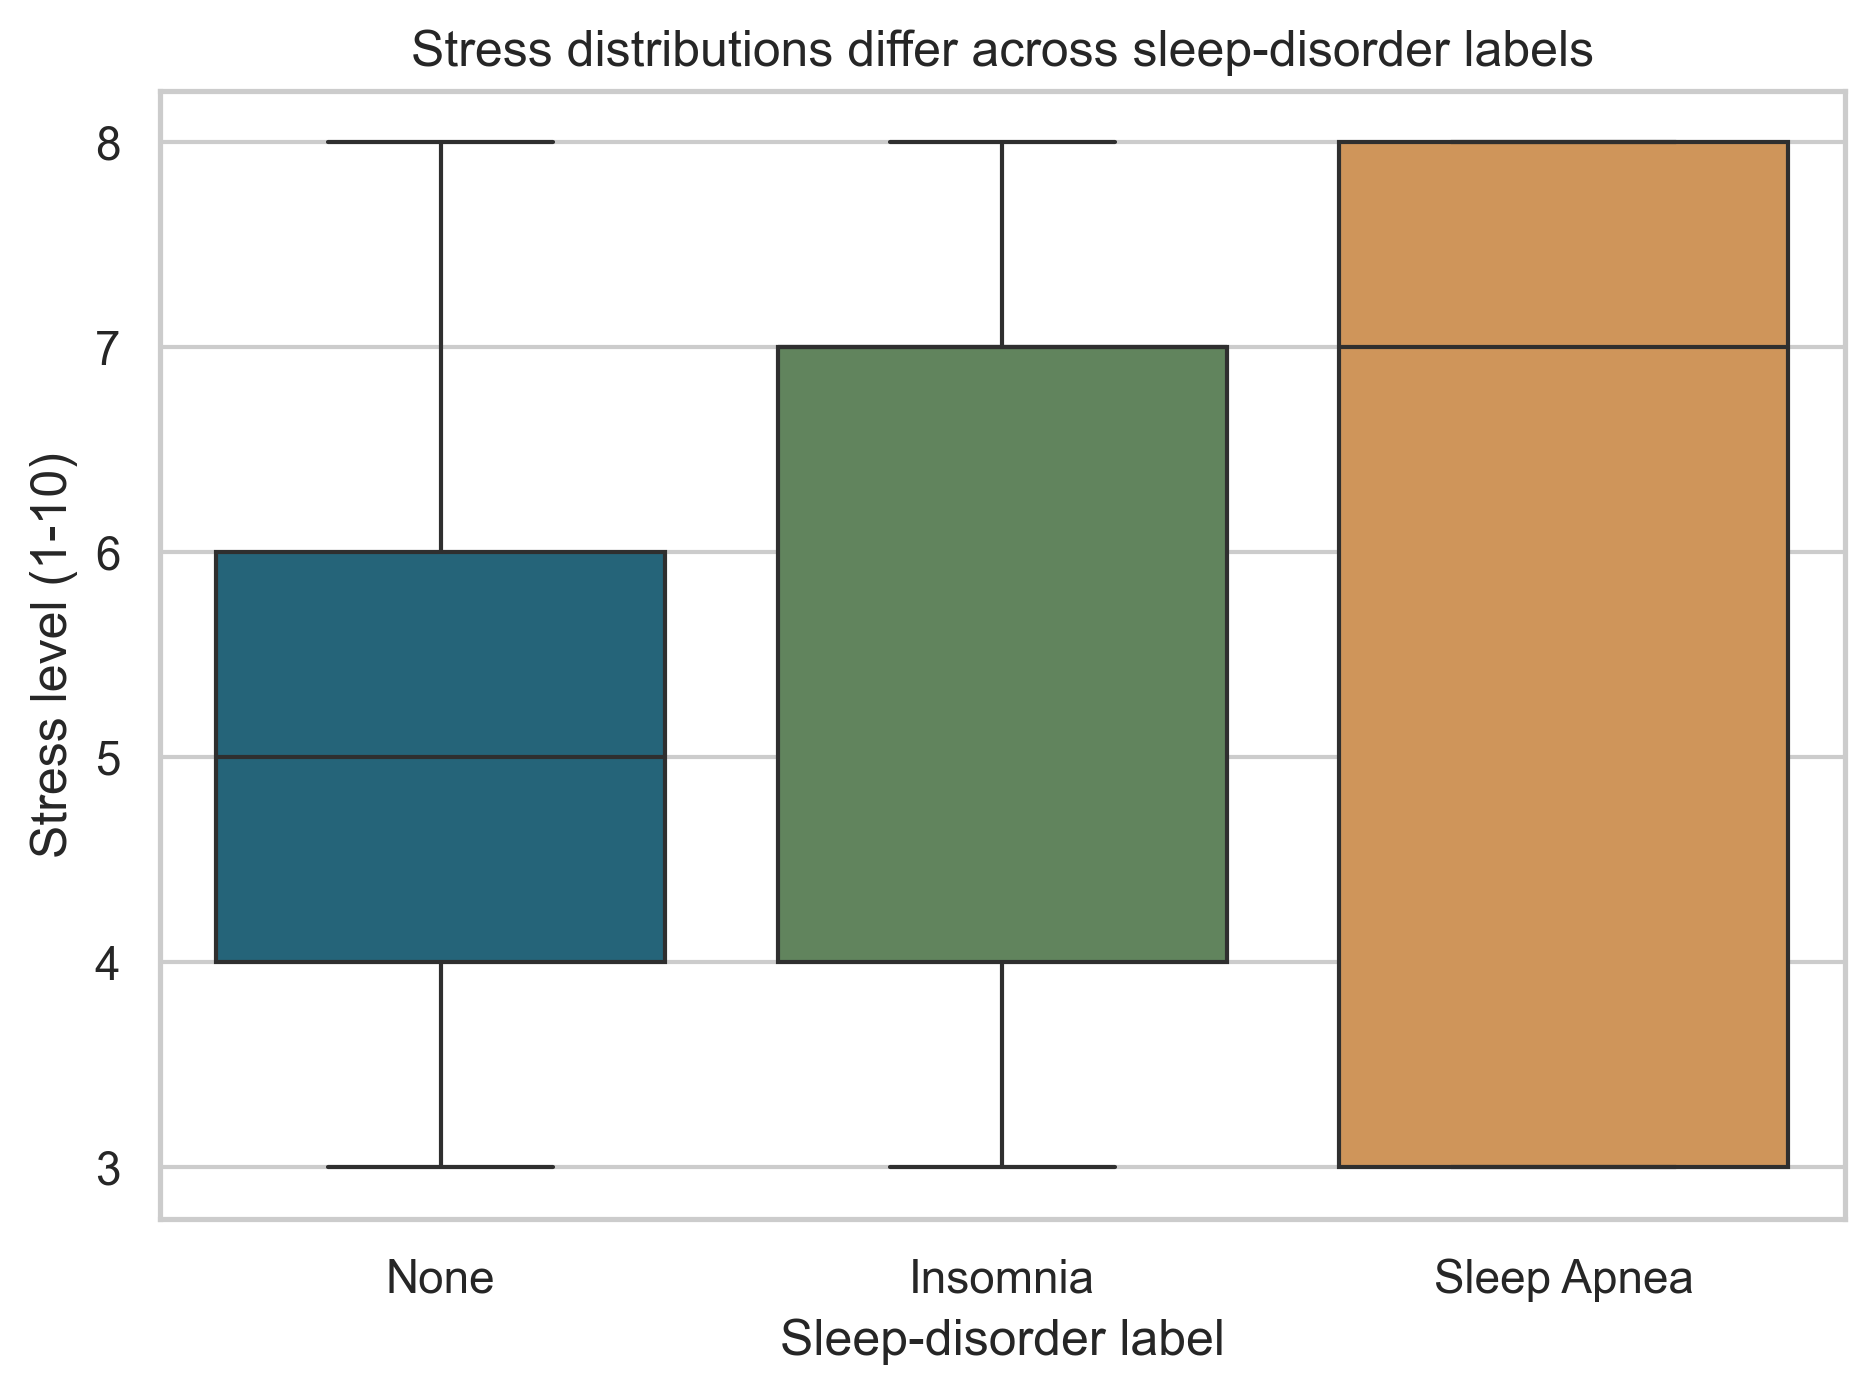

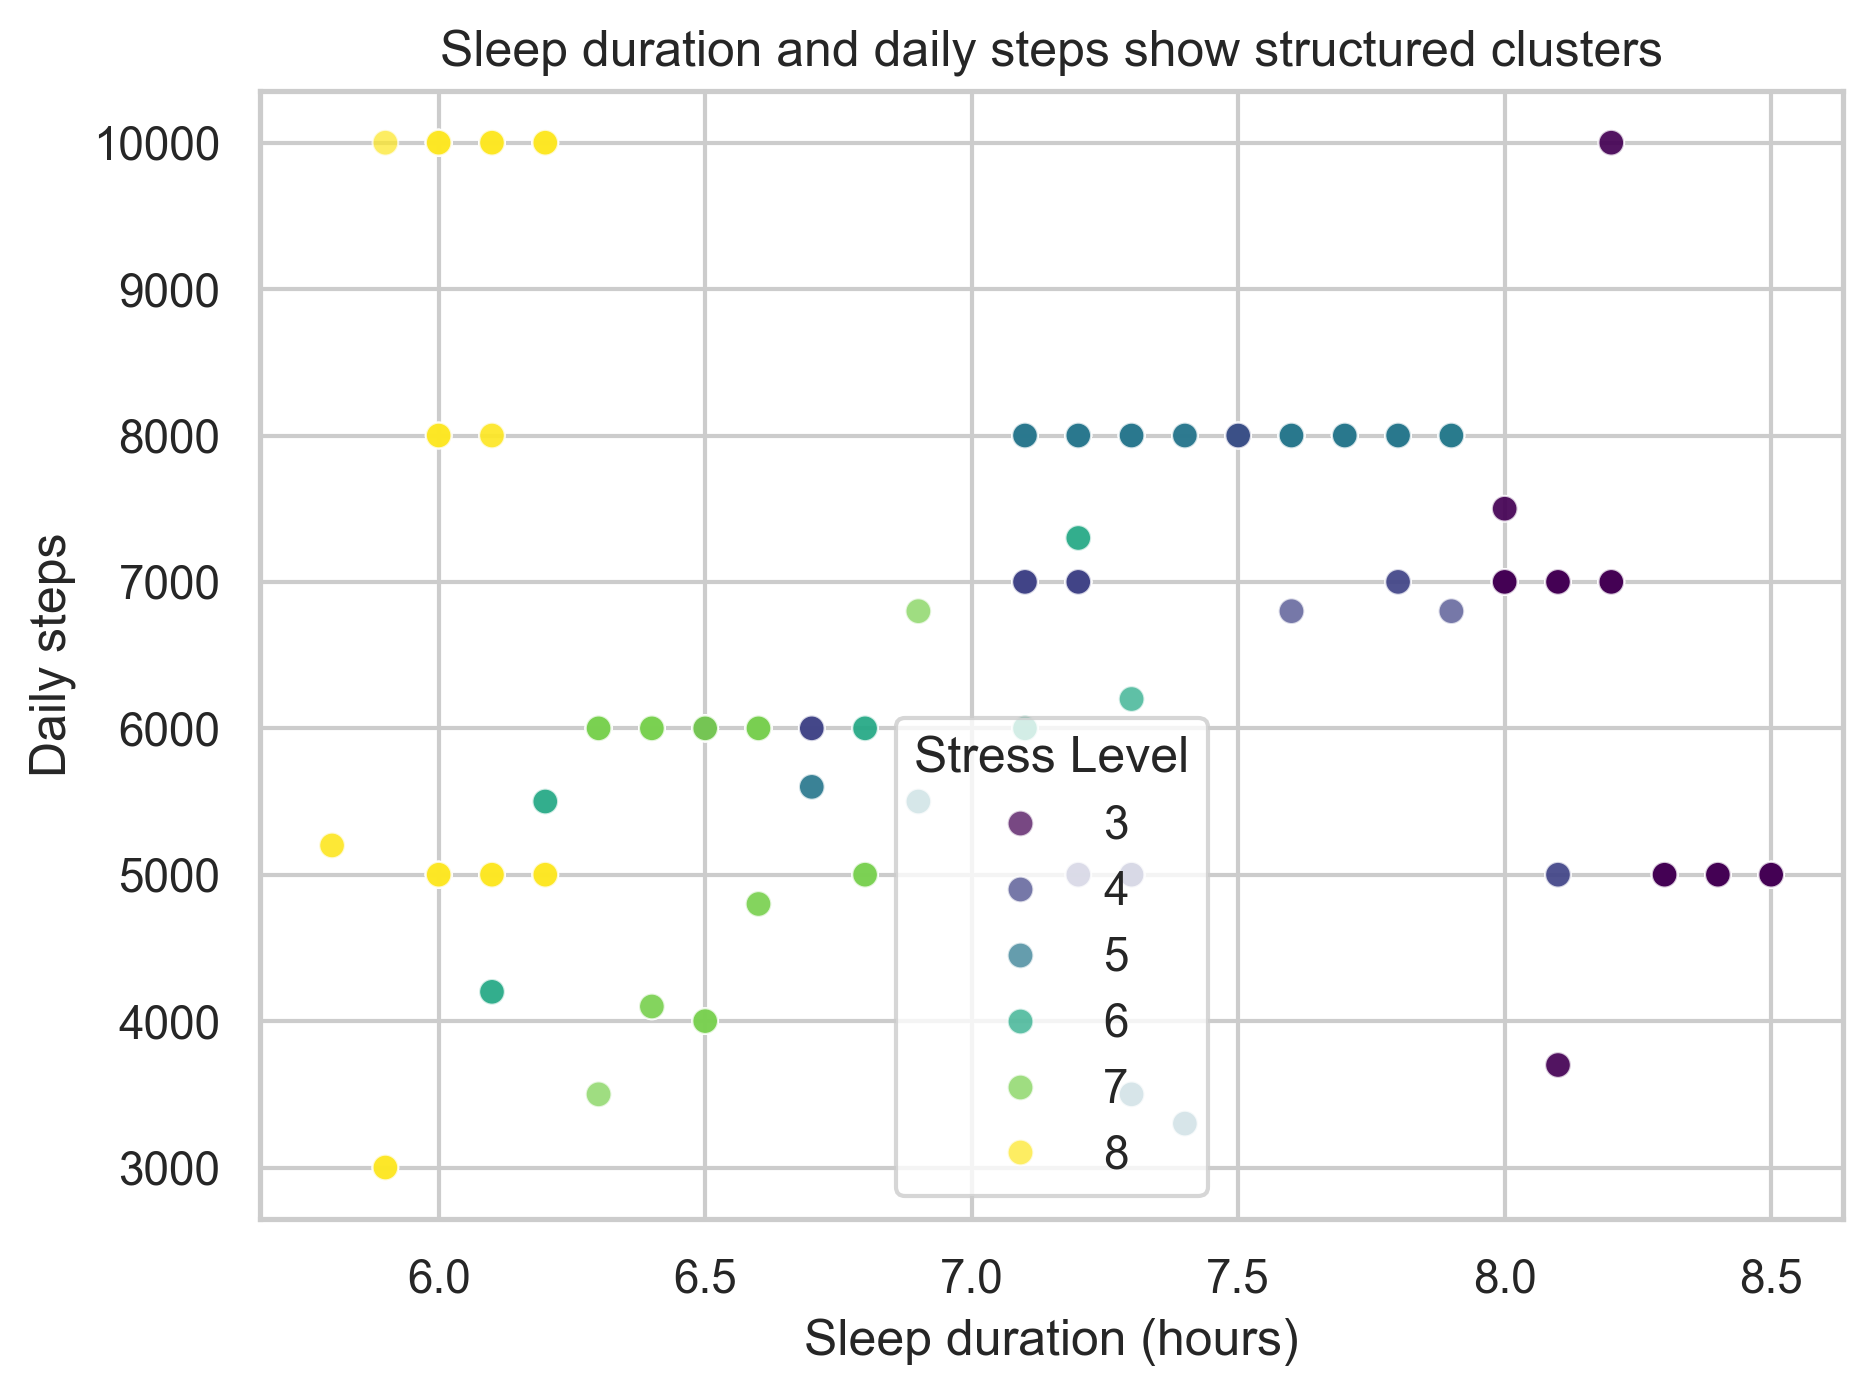

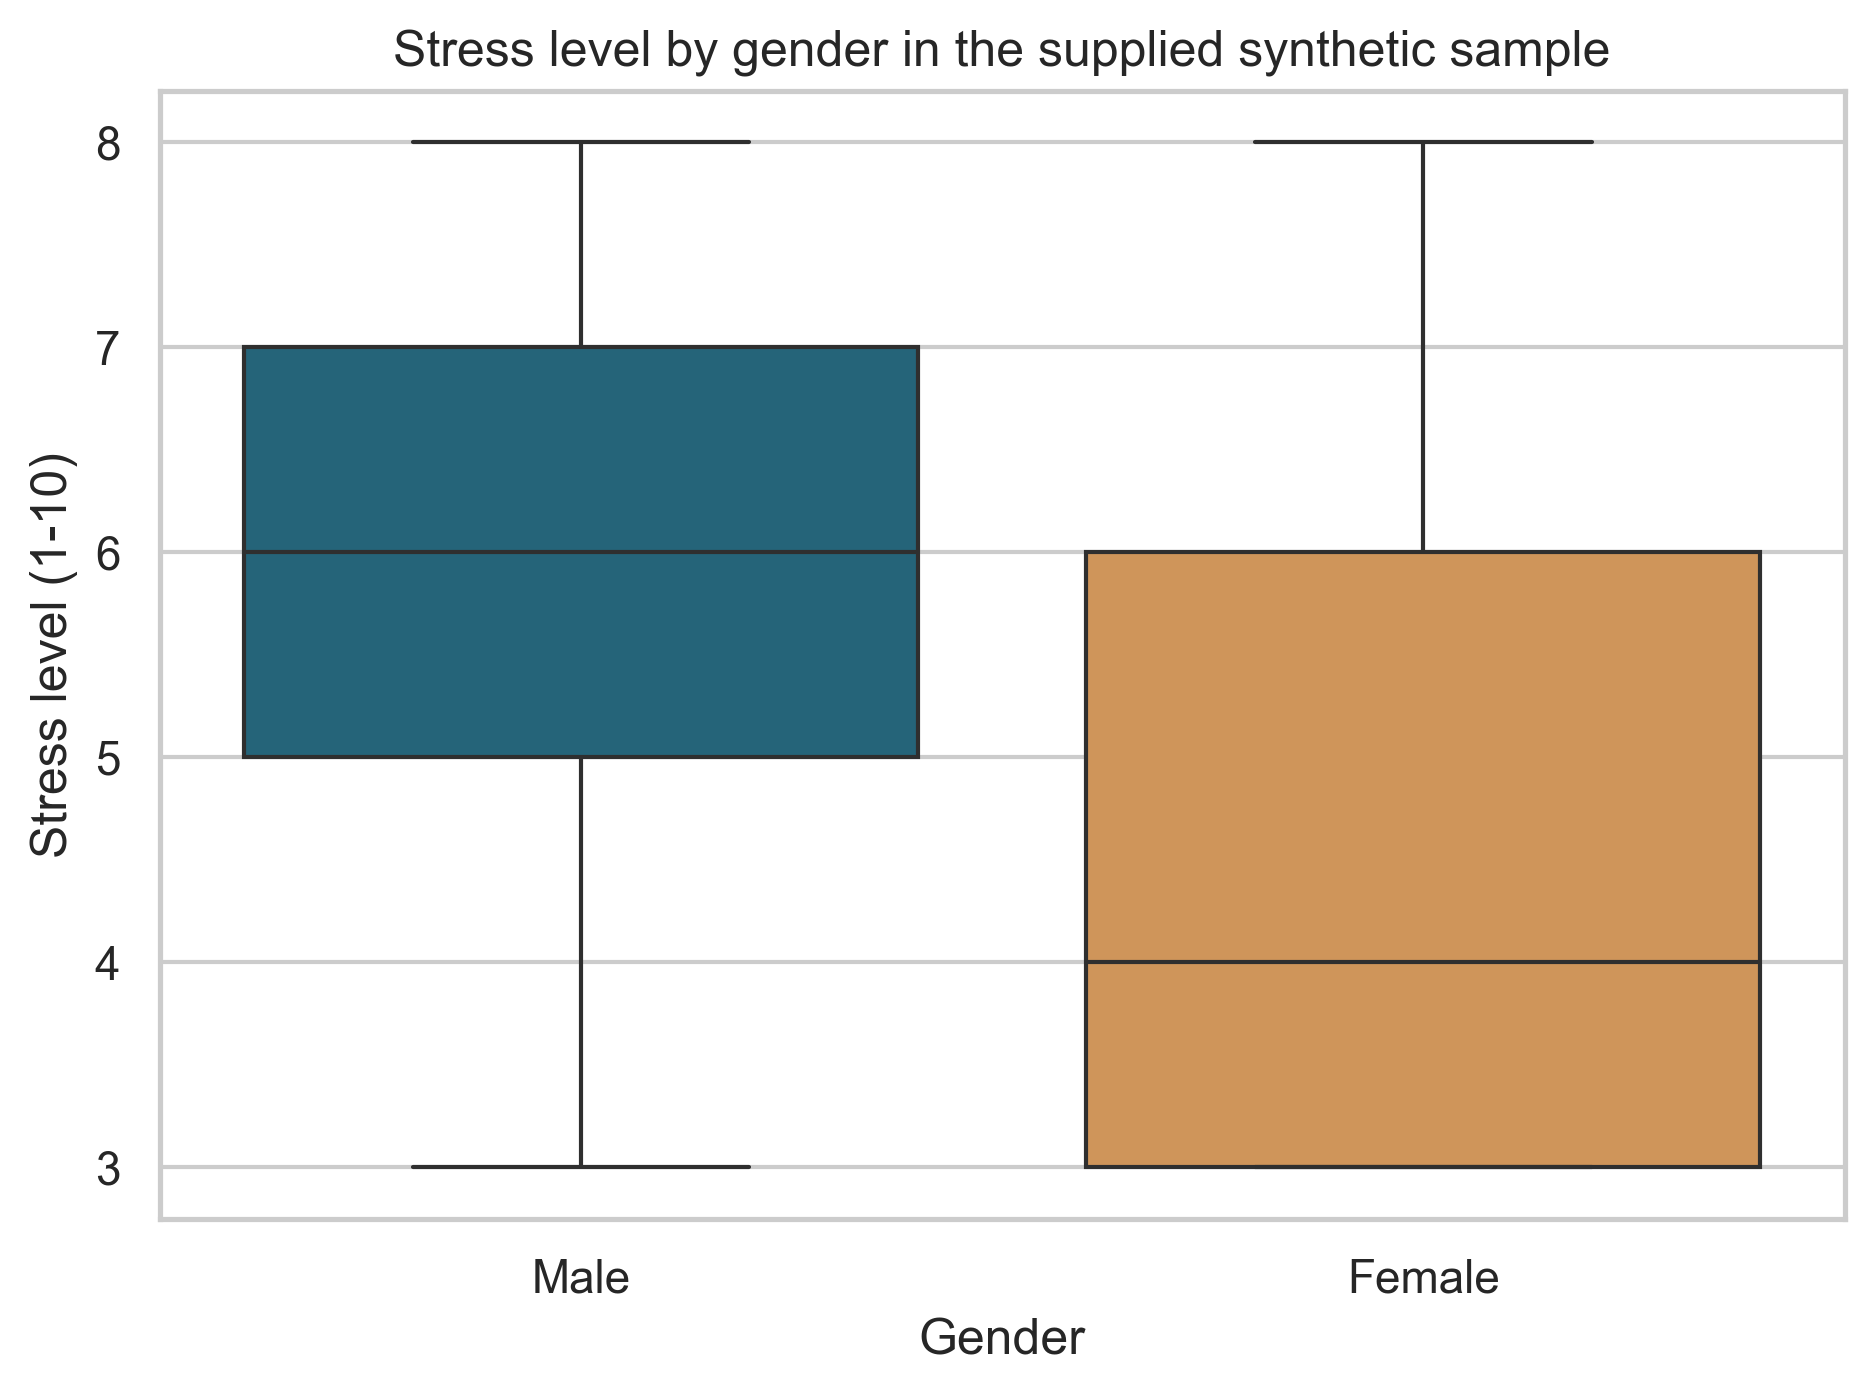

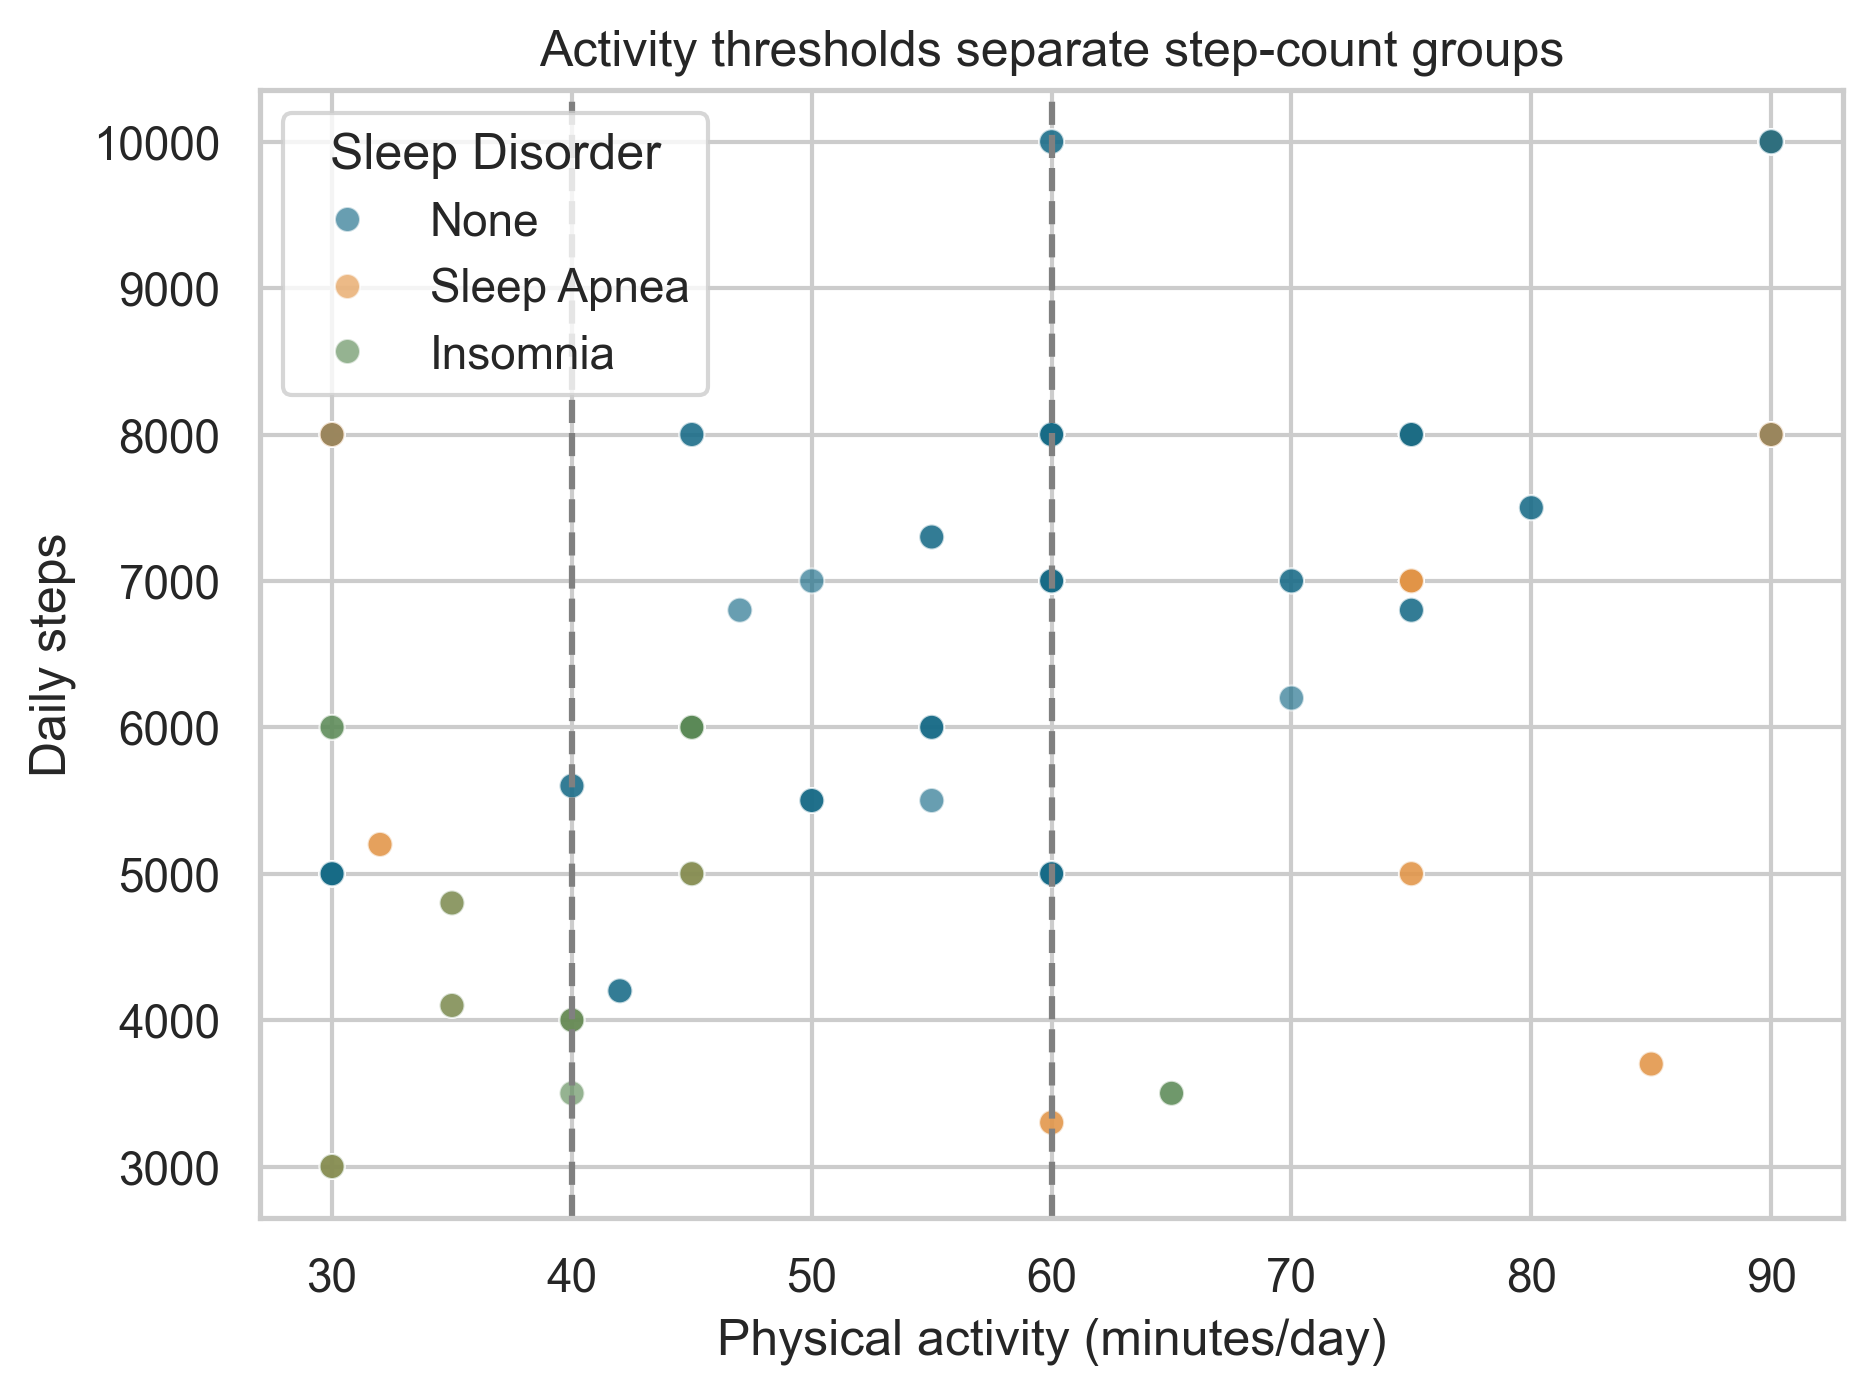

In [3]:
for name in ['01_stress_disorder','02_sleep_steps','03_stress_gender','04_activity_steps']:
    display(Image(filename=str(FIG/f'{name}.png'), width=650))

**Reading the results.** Gender stress distributions differ in this file, high-activity records show more steps, and no-disorder records have longer mean sleep. The men's stress-3 comparison has only four observations in its low-stress group; its one-sided p is about 0.051. Its bootstrap CI and Welch p use different approximations and should not be treated as interchangeable. None of these comparisons identifies a causal effect.

## 2 | Operating characteristic curve

The **original assignment** says reject a batch when the 60-item sample contains **at least four defectives**. Thus accept for D ≤ 3. The English planning brief gives a conflicting rule, resolved here using the original source. Under the requested binomial approximation, D ~ Binomial(60,p), and P(accept|p) is the binomial CDF at 3. Exact sampling without replacement from a lot of 2,000 would use a hypergeometric model.

P(reject | p=5%) = 0.3527
P(accept | p=2%) = 0.9678


,Defect rate,P(accept)
0,0.01,0.99688
1,0.02,0.96781
2,0.03,0.89426
3,0.05,0.64728
4,0.10,0.13740
5,0.15,0.01483
6,0.20,0.00101


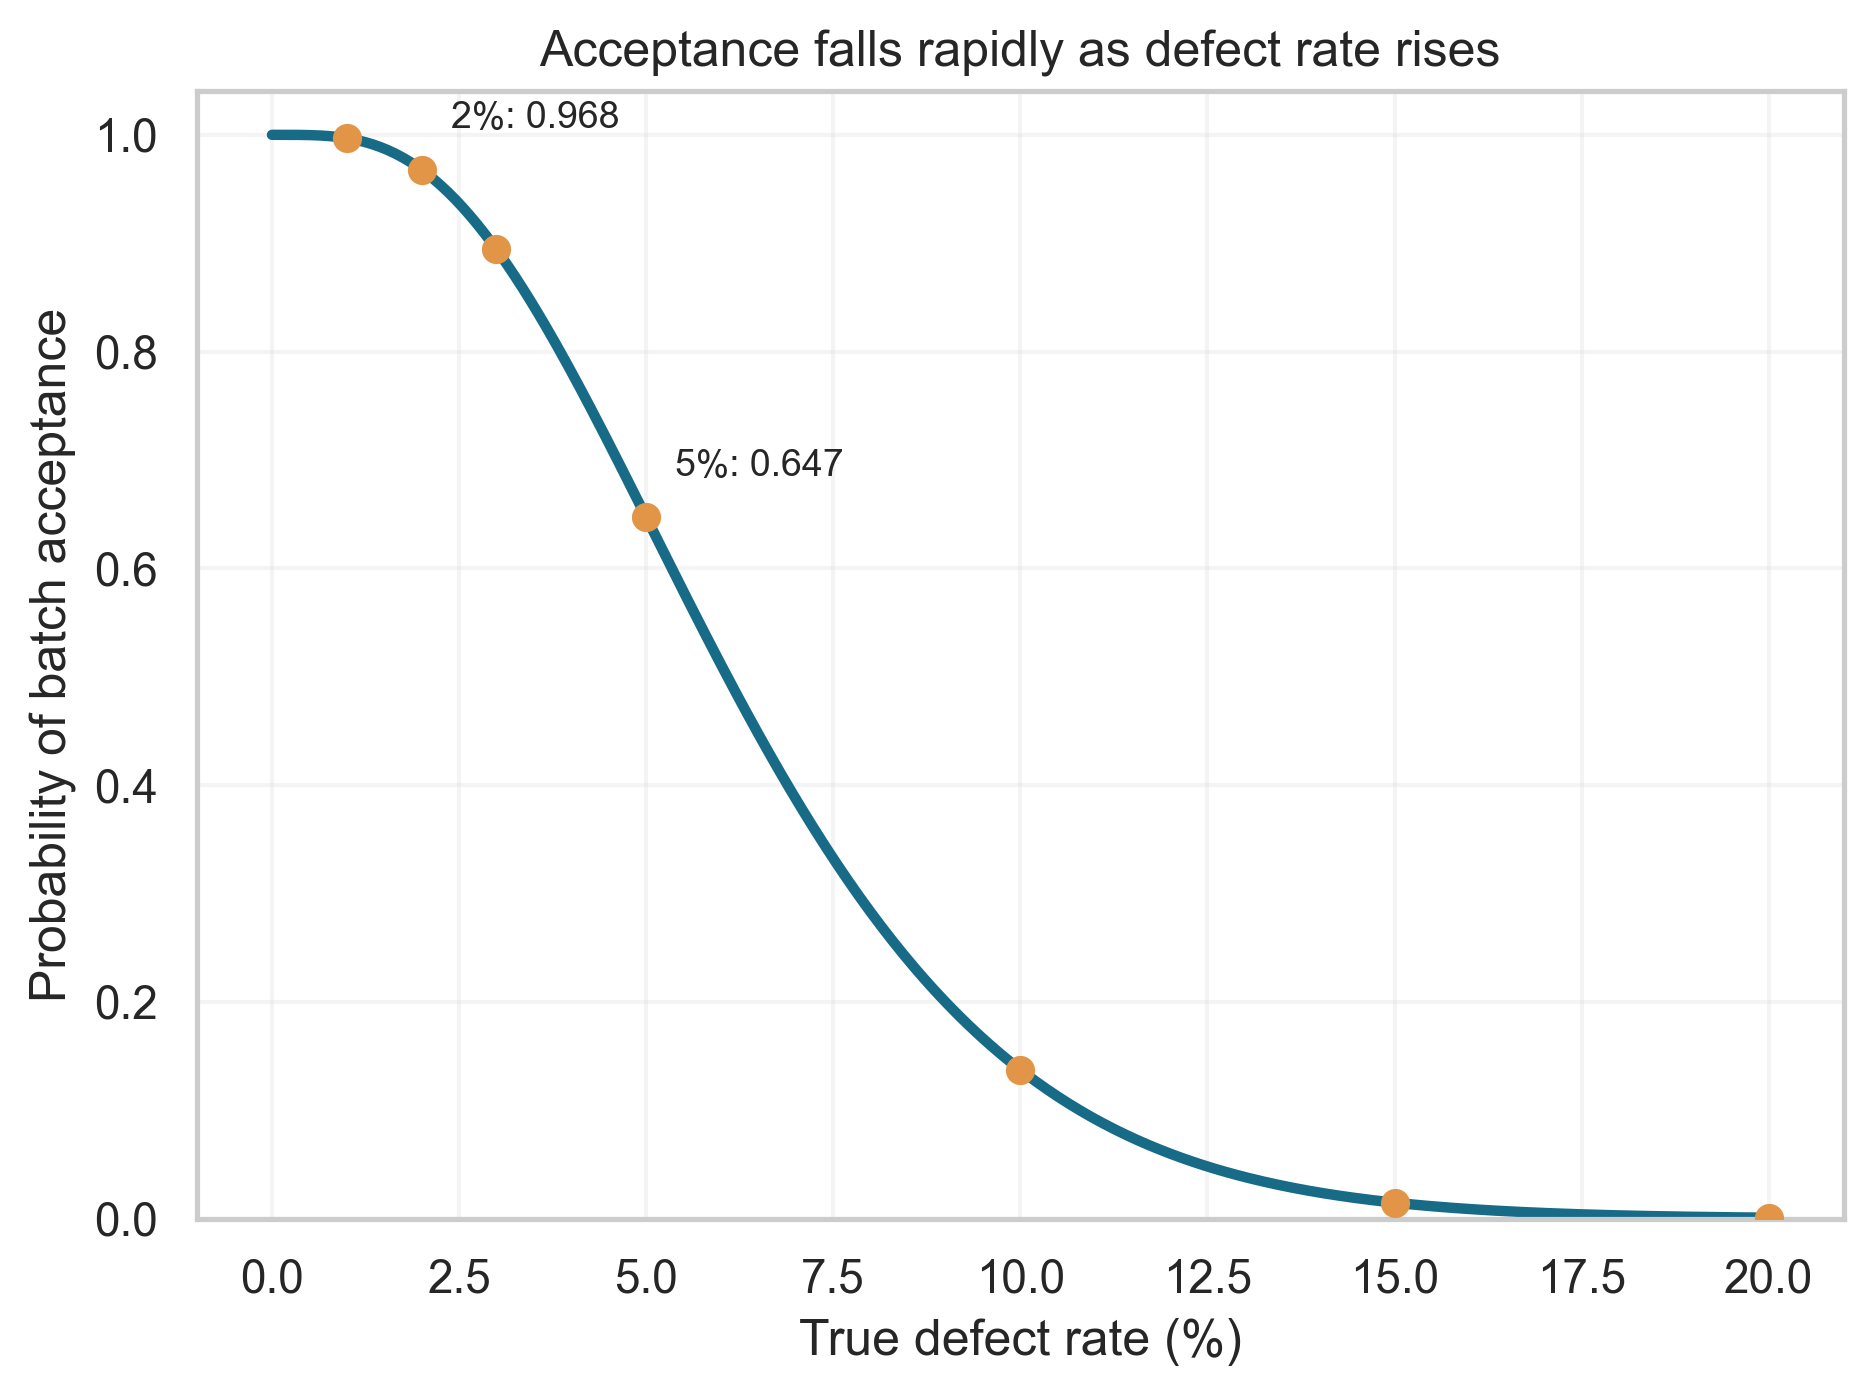

In [4]:
O = R['module2']
display(pd.DataFrame({'Defect rate':O['p'], 'P(accept)':O['acceptance']}).round(5))
print(f"P(reject | p=5%) = {O['reject_at_5pct']:.4f}")
print(f"P(accept | p=2%) = {O['accept_at_2pct']:.4f}")
display(Image(filename=str(FIG/'05_oc_curve.png'), width=700))

**Interpretation.** At 2% defects, about 96.8% of batches are accepted. At 5%, about 35.3% are rejected. Producer and consumer risk depend on which defect rates are defined as acceptable and unacceptable quality.

## 3 | Normal theory and transformations

Assume height X ~ Normal(182, 8²) cm. For 175 < X < 195, the z endpoints are −0.875 and 1.625. Simulate 1,200 heights; compare raw, log, and Box–Cox Q–Q patterns. Box–Cox selects its parameter from this sample, so in-sample fit improvement is not independent evidence of nonnormality.

P(175 < X < 195): 0.757132
Sample mean, SD: 181.761 7.915
Box-Cox lambda: 0.503


,Scale,QQ R²,Shapiro p
0,Raw,0.99898,0.41913
1,Log,0.99899,0.42652
2,Box-Cox,0.99921,0.58420


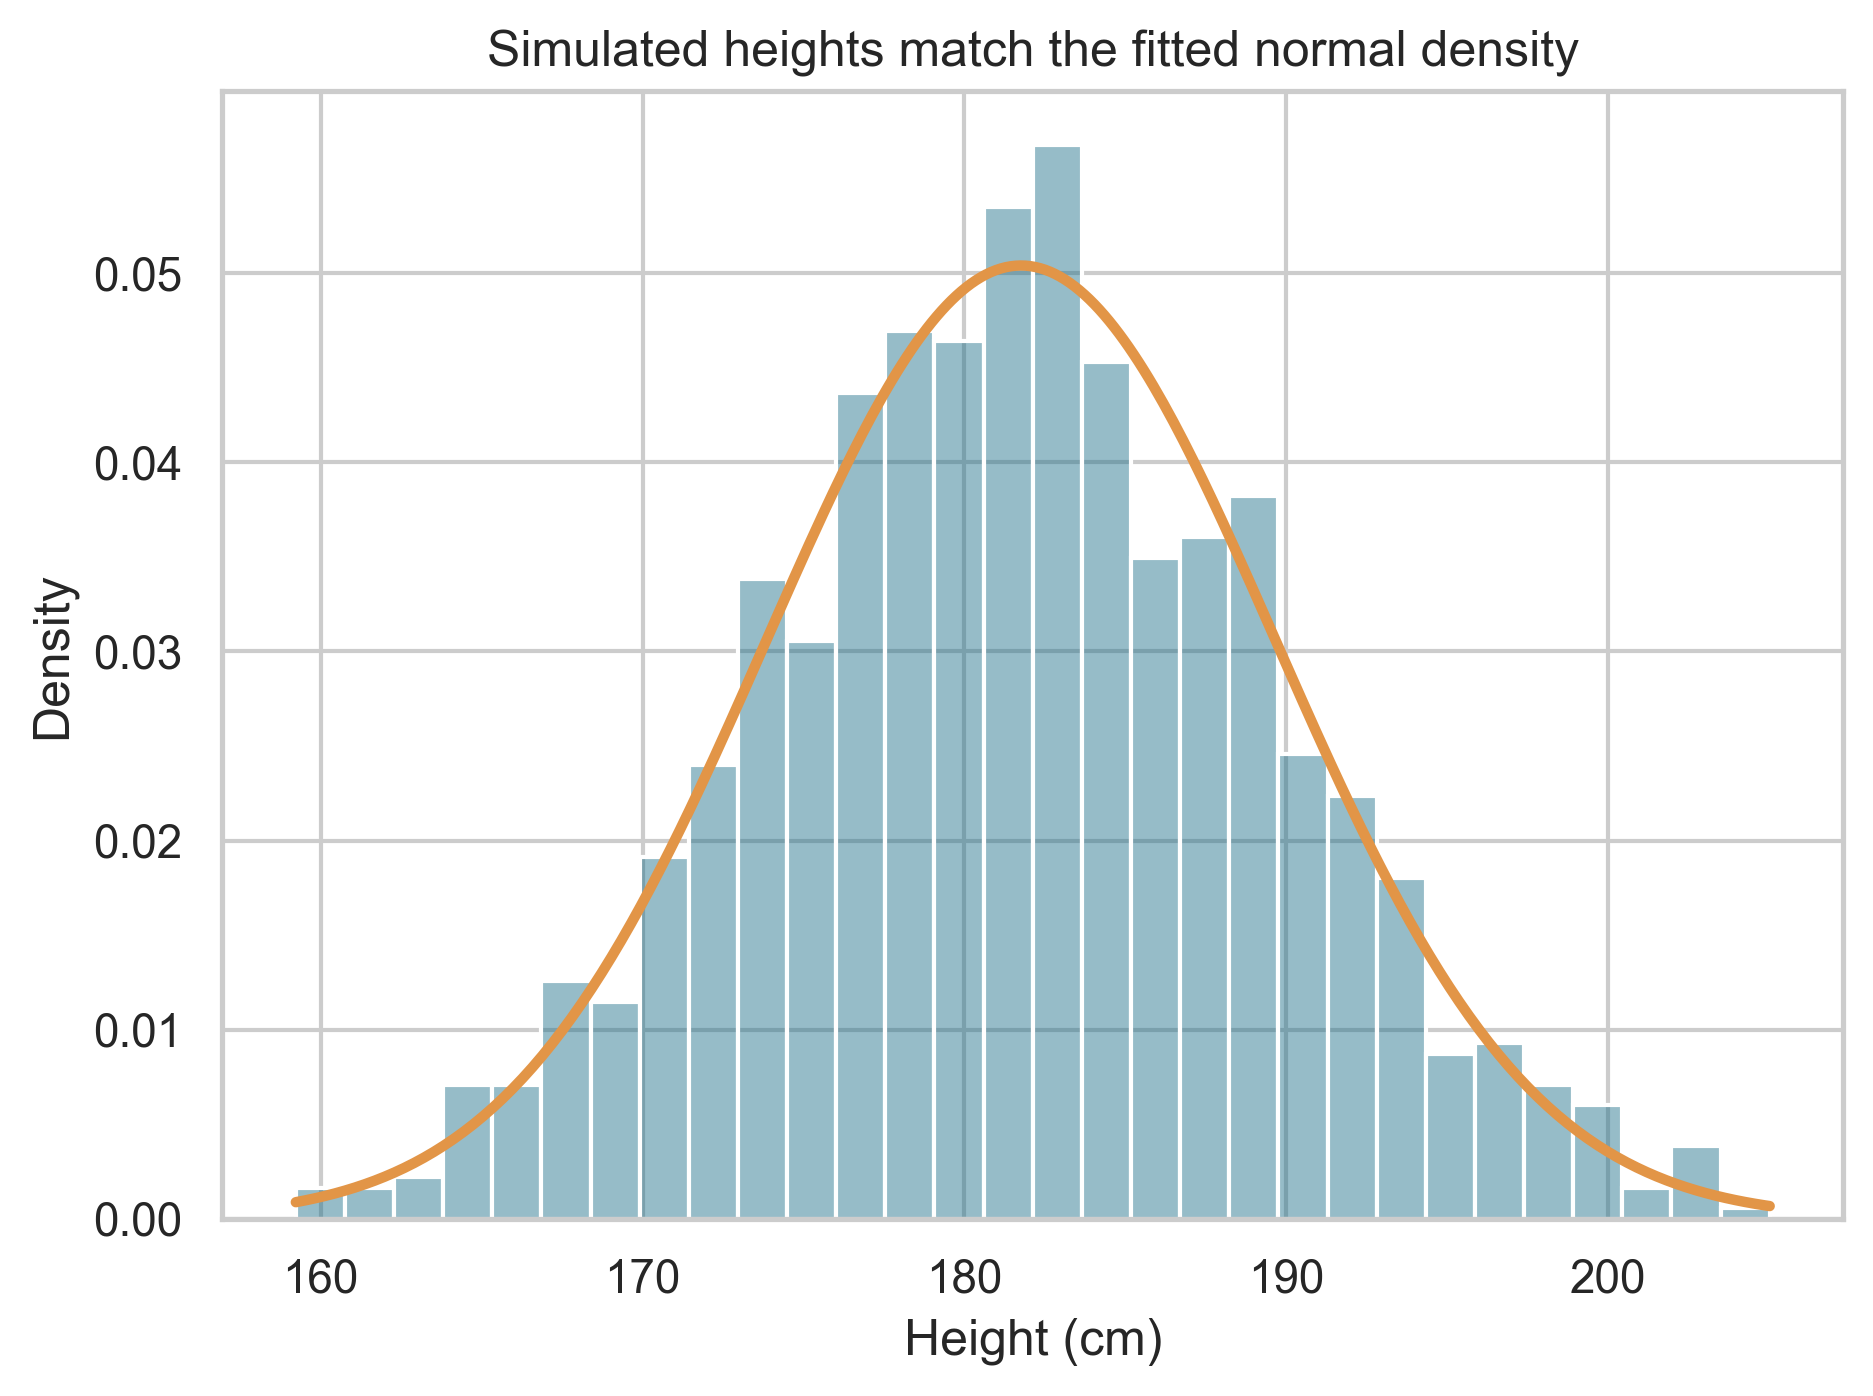

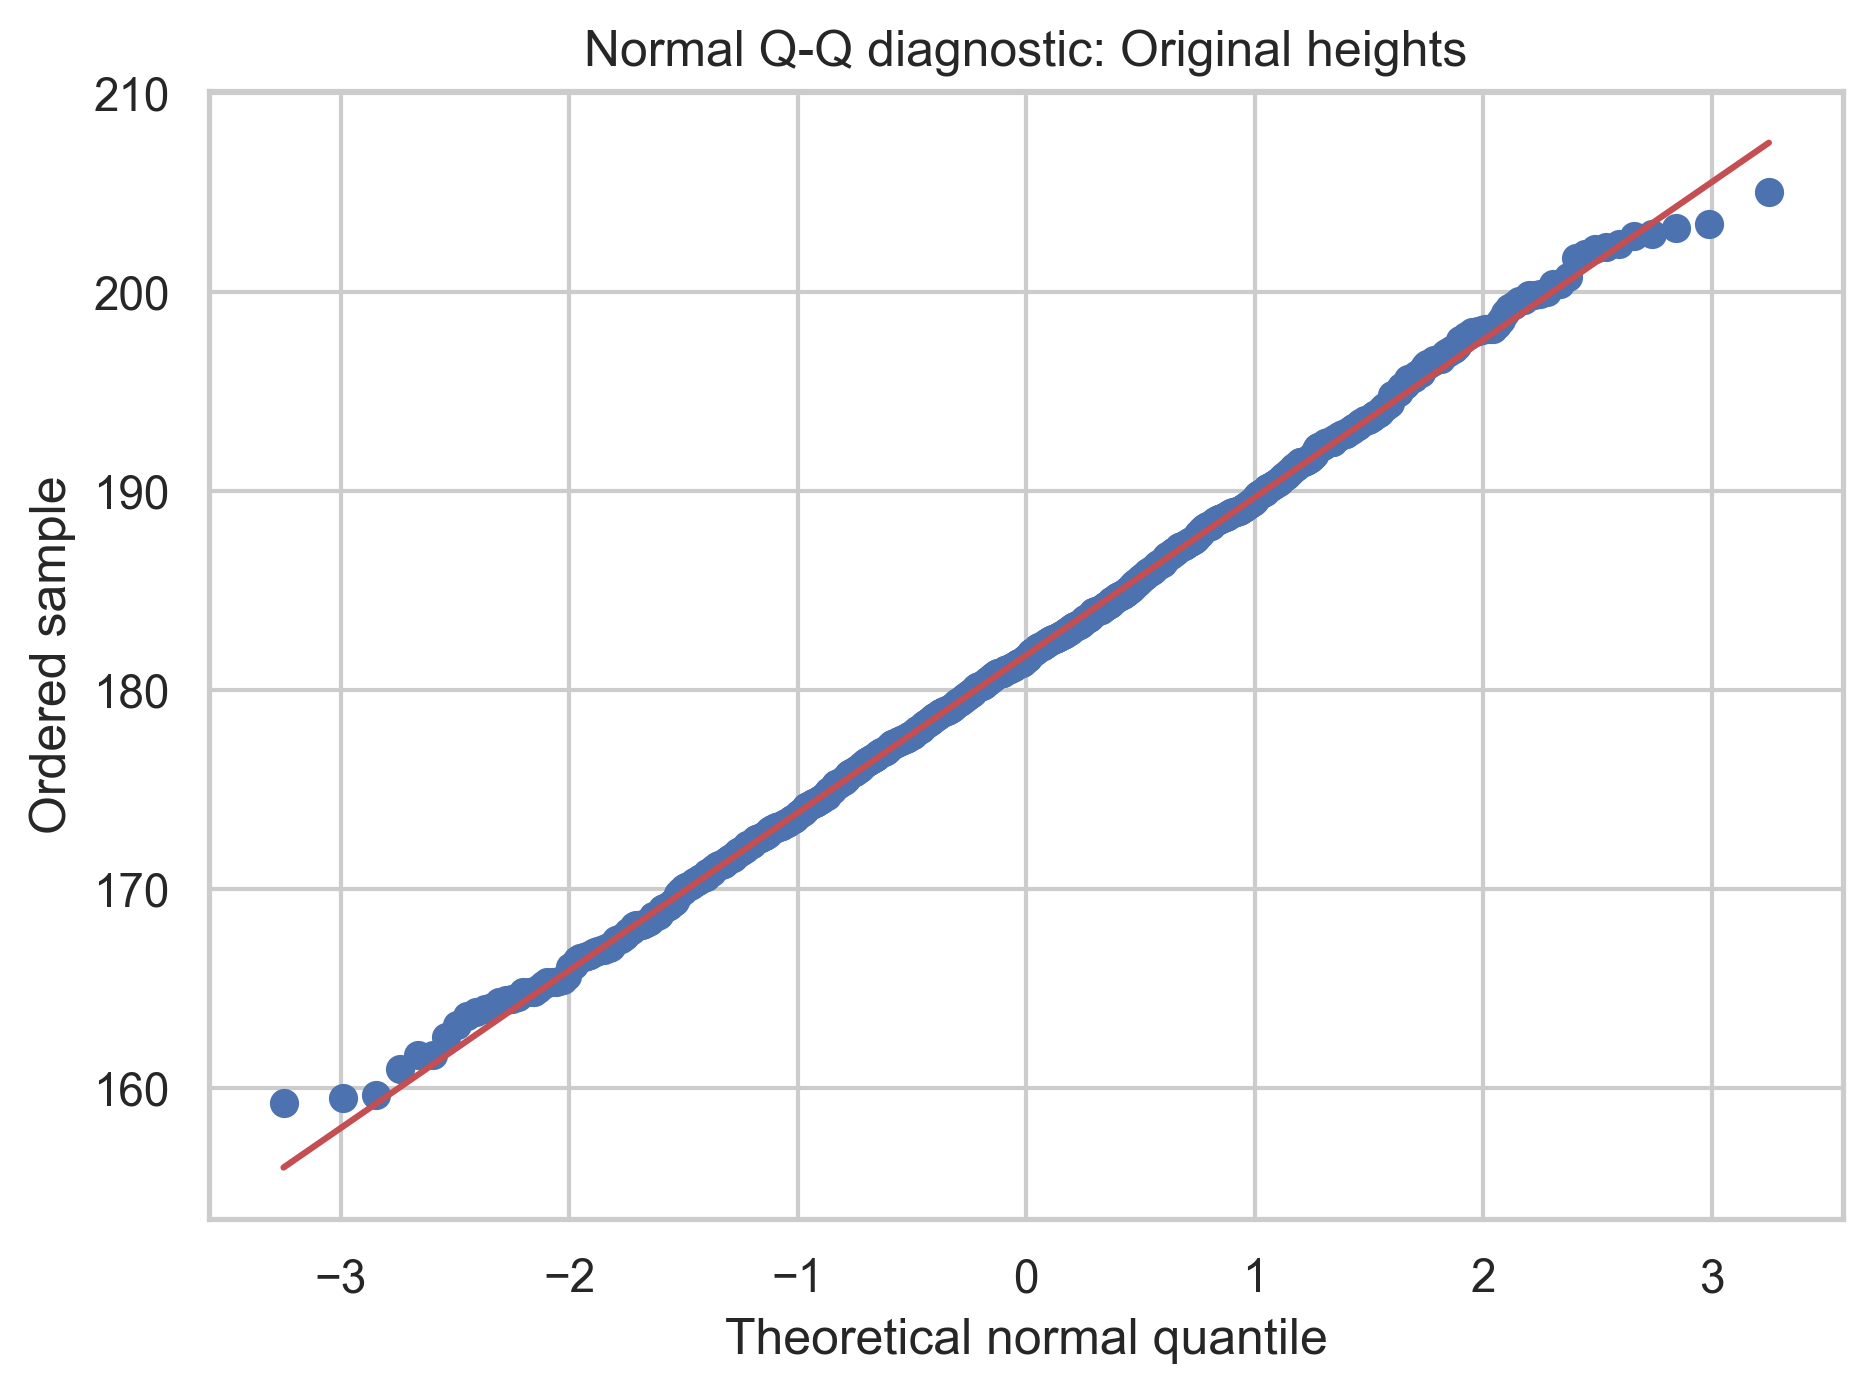

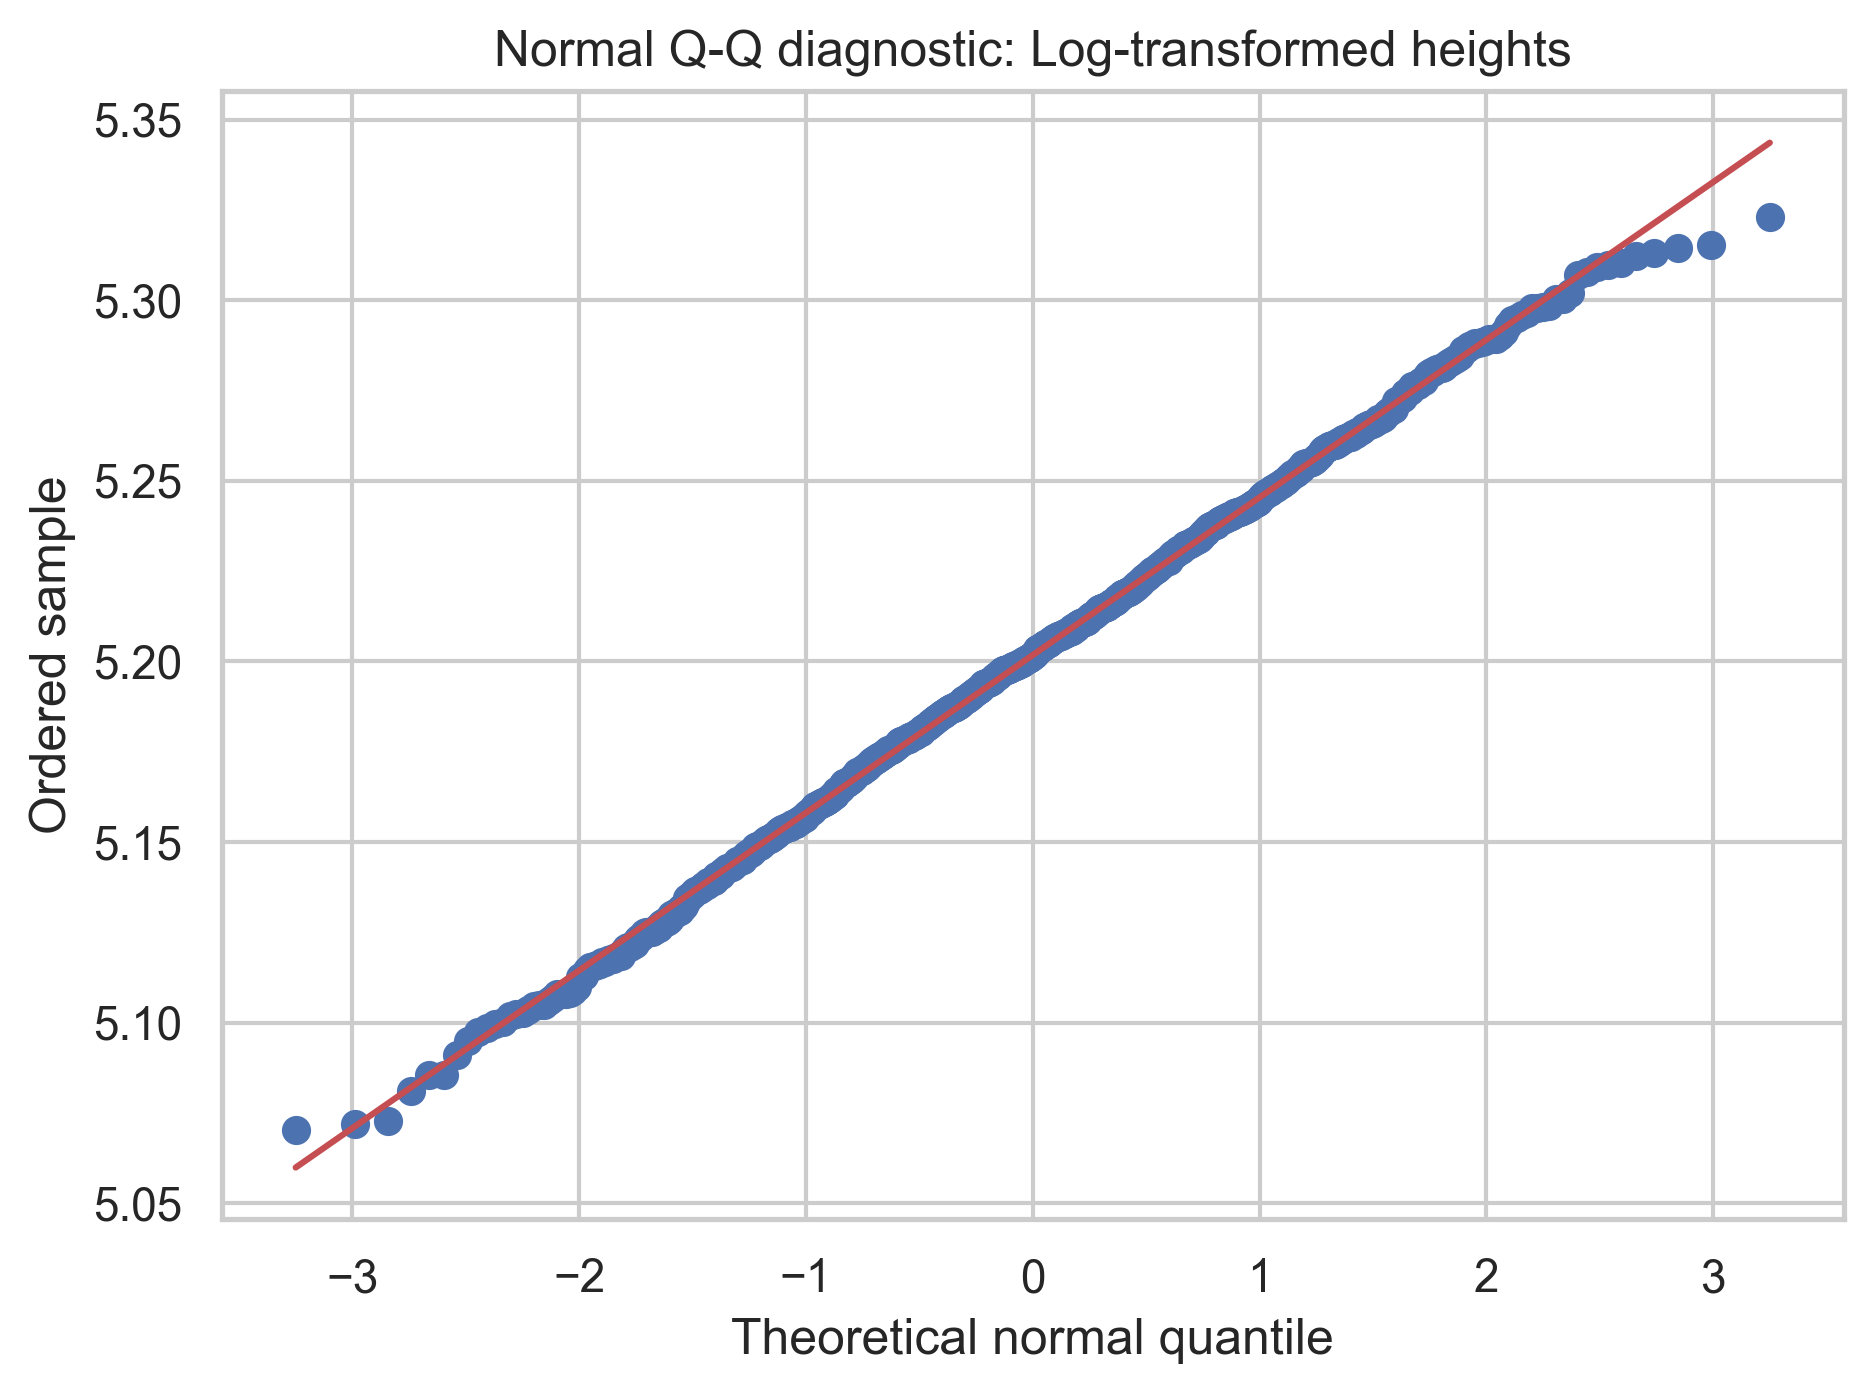

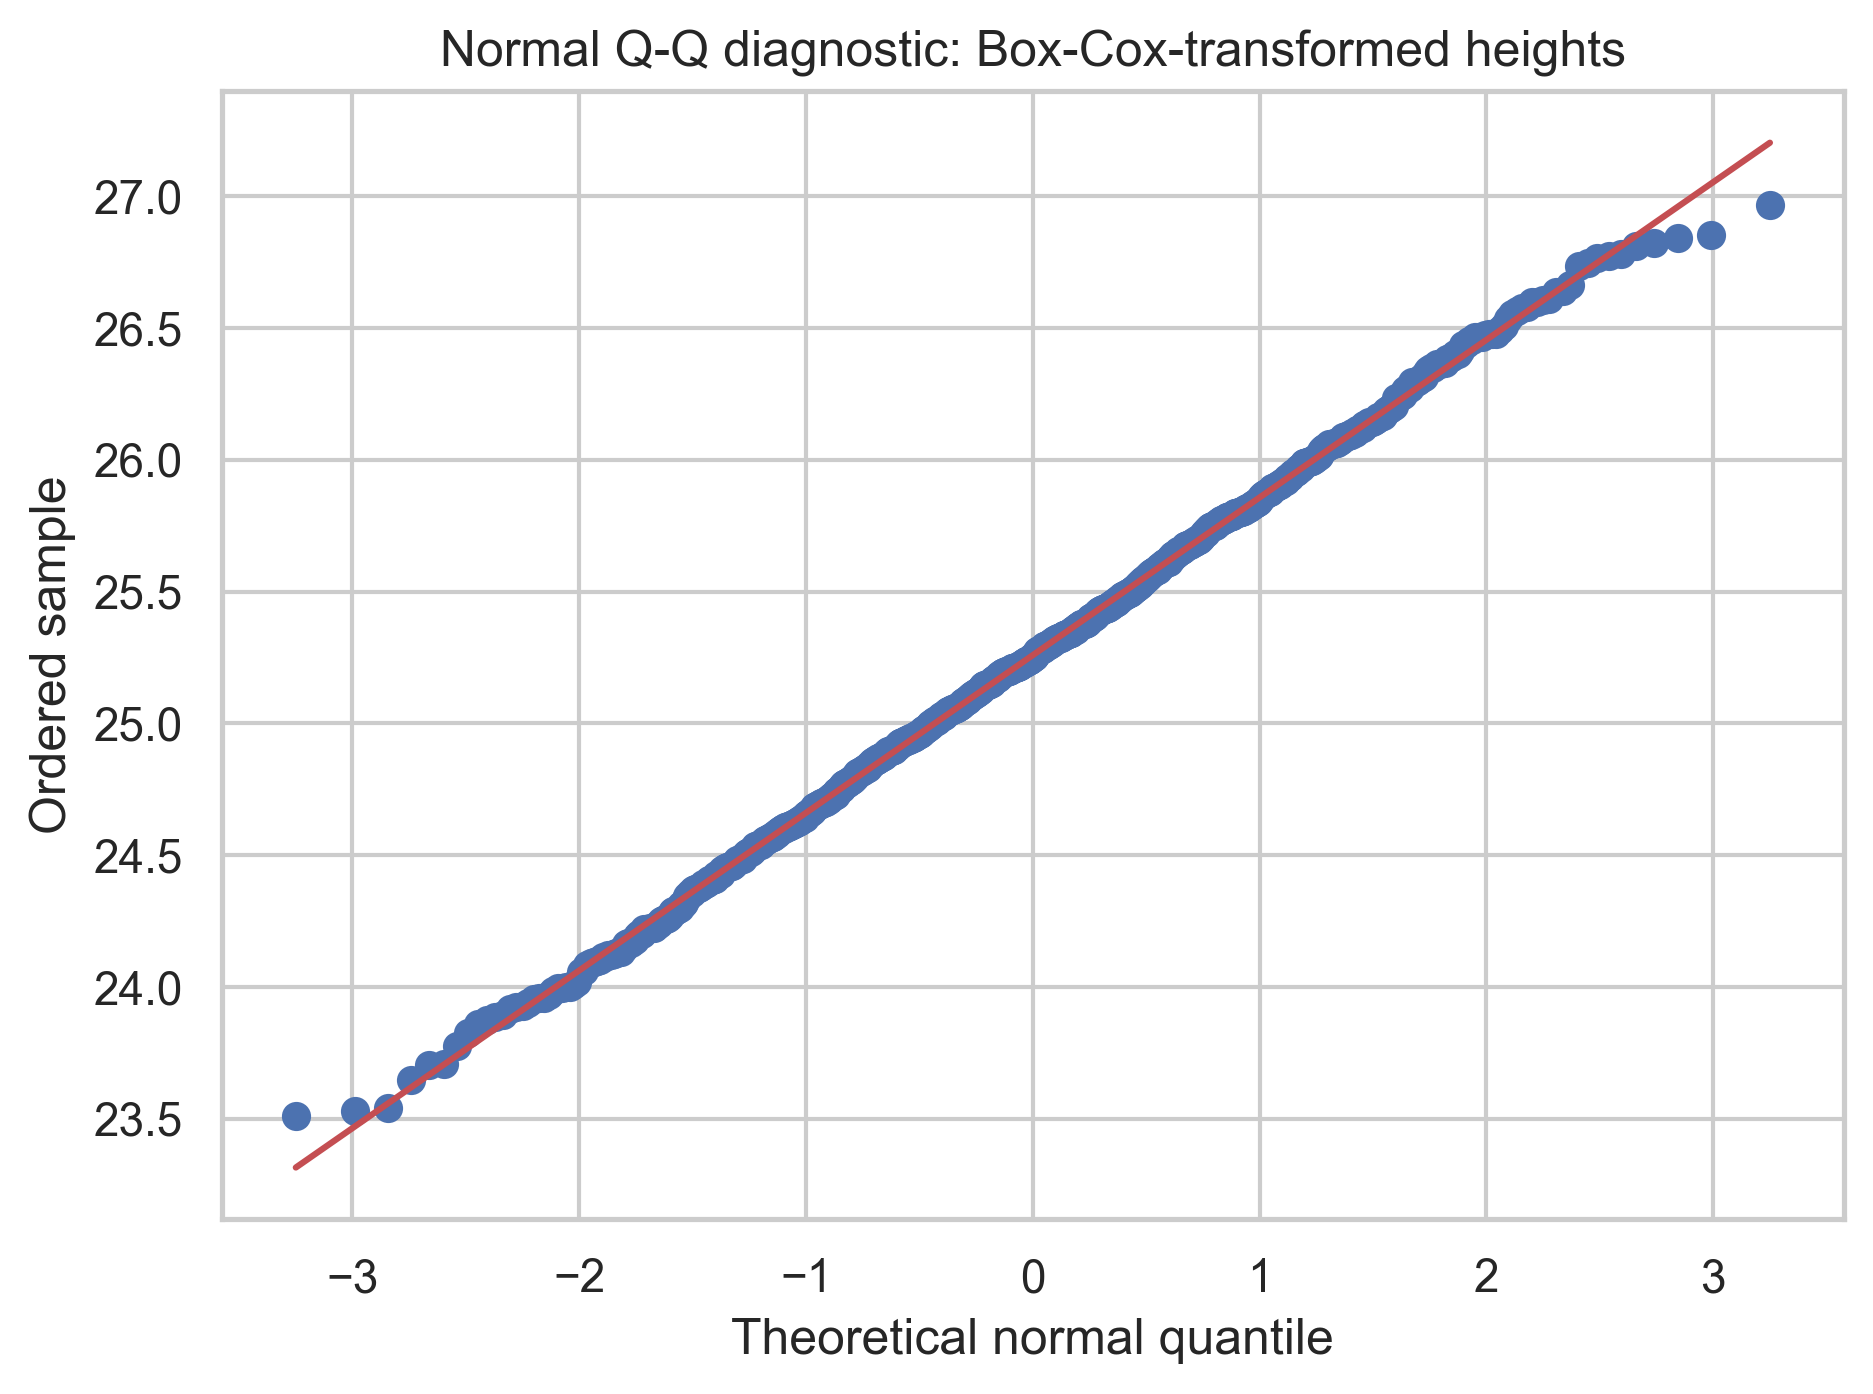

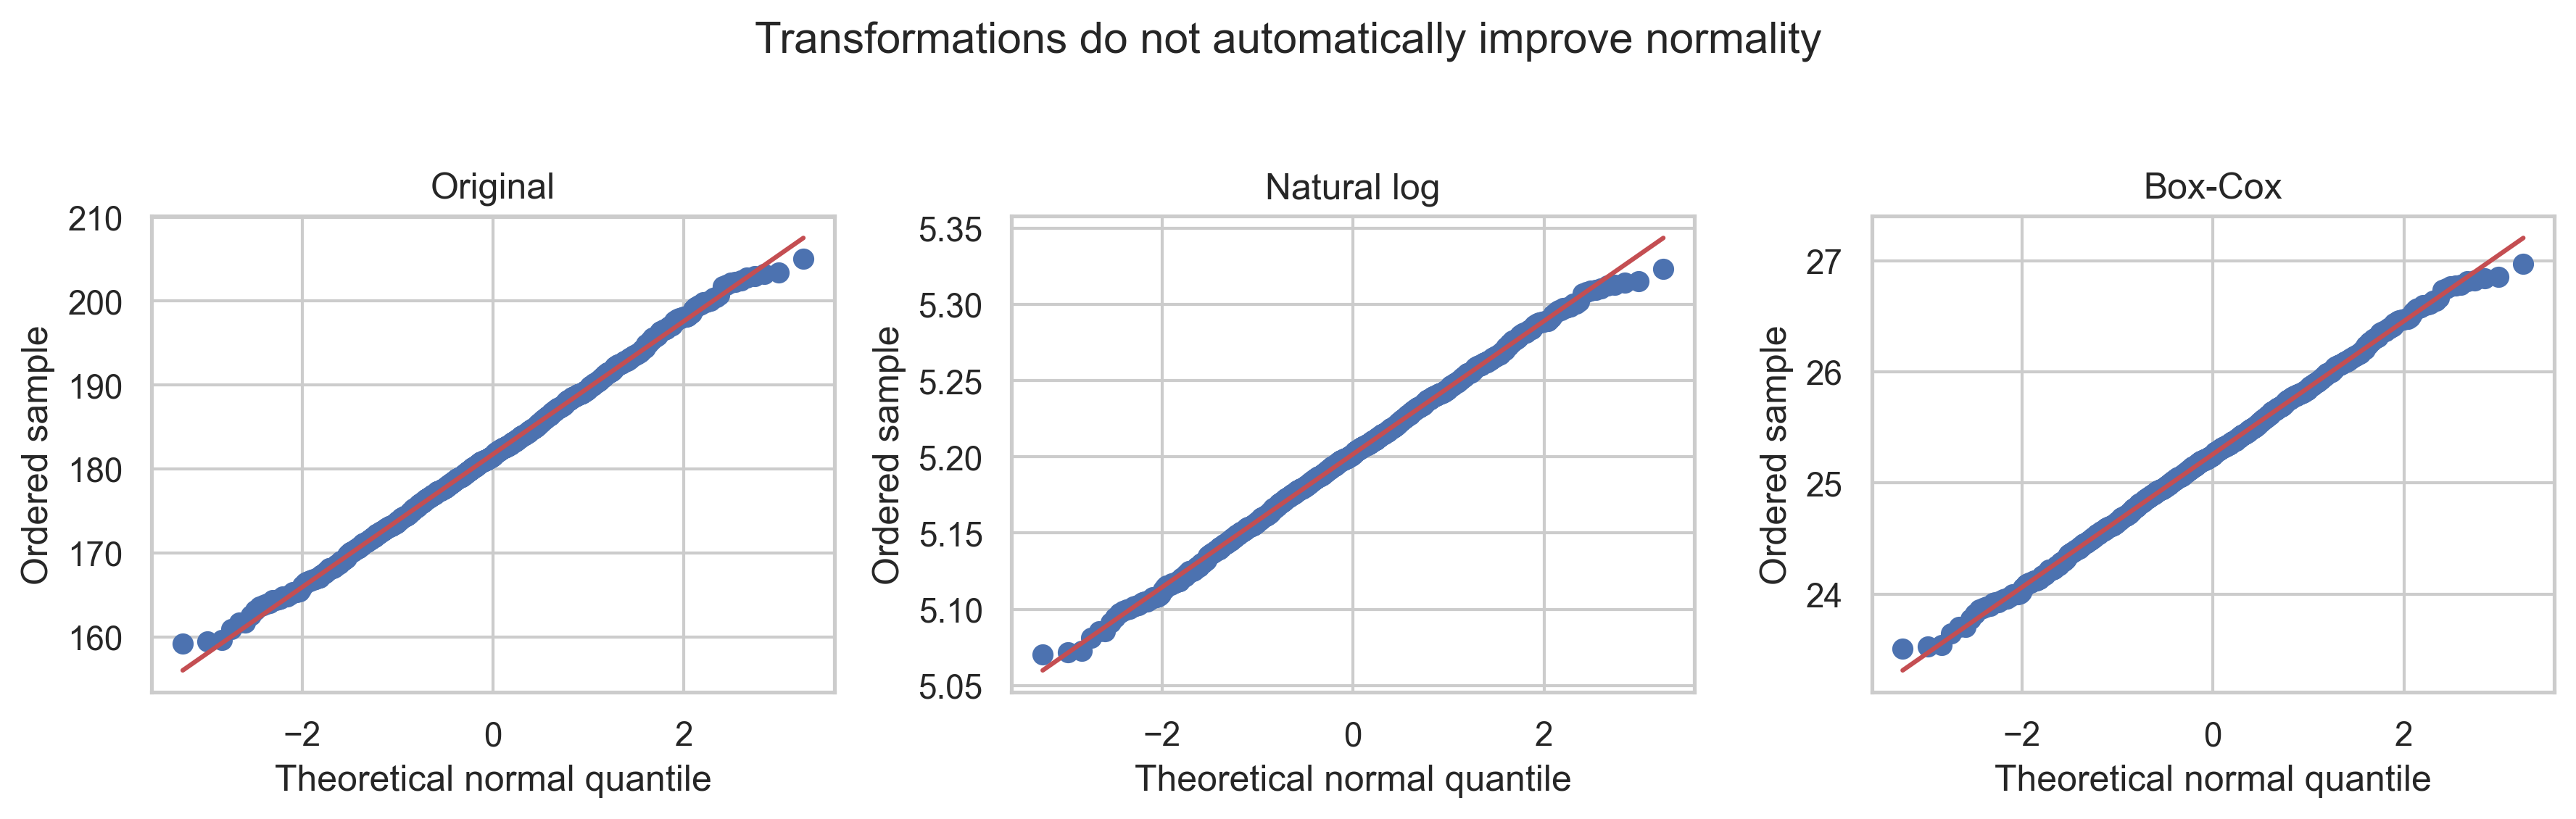

In [5]:
H = R['module3']
print('P(175 < X < 195):', round(H['probability_175_195'],6))
print('Sample mean, SD:', round(H['sample_mean'],3), round(H['sample_sd'],3))
print('Box-Cox lambda:', round(H['boxcox_lambda'],3))
display(pd.DataFrame({'Scale':['Raw','Log','Box-Cox'], 'QQ R²':H['qq_r2'],
                      'Shapiro p':H['shapiro_p']}).round(5))
for name in ['06_height_histogram','07a_height_qq_raw','07b_height_qq_log',
             '07c_height_qq_boxcox','07_height_qq_comparison']:
    display(Image(filename=str(FIG/f'{name}.png'), width=850))

**Interpretation.** The raw sample is already compatible with normality. Box–Cox produces a marginally straighter Q–Q plot in this one simulated sample, while all Shapiro p-values exceed 0.05. This does not justify transforming an already Gaussian population by default.

## 4 | Test preparation and math

H0: mean math scores are equal across preparation groups; H1: different, at alpha = 0.01. Welch's test is a robust mean-comparison default even though Levene does not reject equal variances here. Future sample size assumes equal group sizes, the observed pooled Cohen d, two-sided noncentral-t power, and an 85% target.

,Completed n,None n,Completed mean,None mean,Welch t,df,p,Cohen d,95% CI for mean difference,Levene p,Required n/group
0,358,642,69.6955,64.0779,5.787,770.0791,0.0,0.3763,"[np.float64(3.765), np.float64(7.444)]",0.4655,186


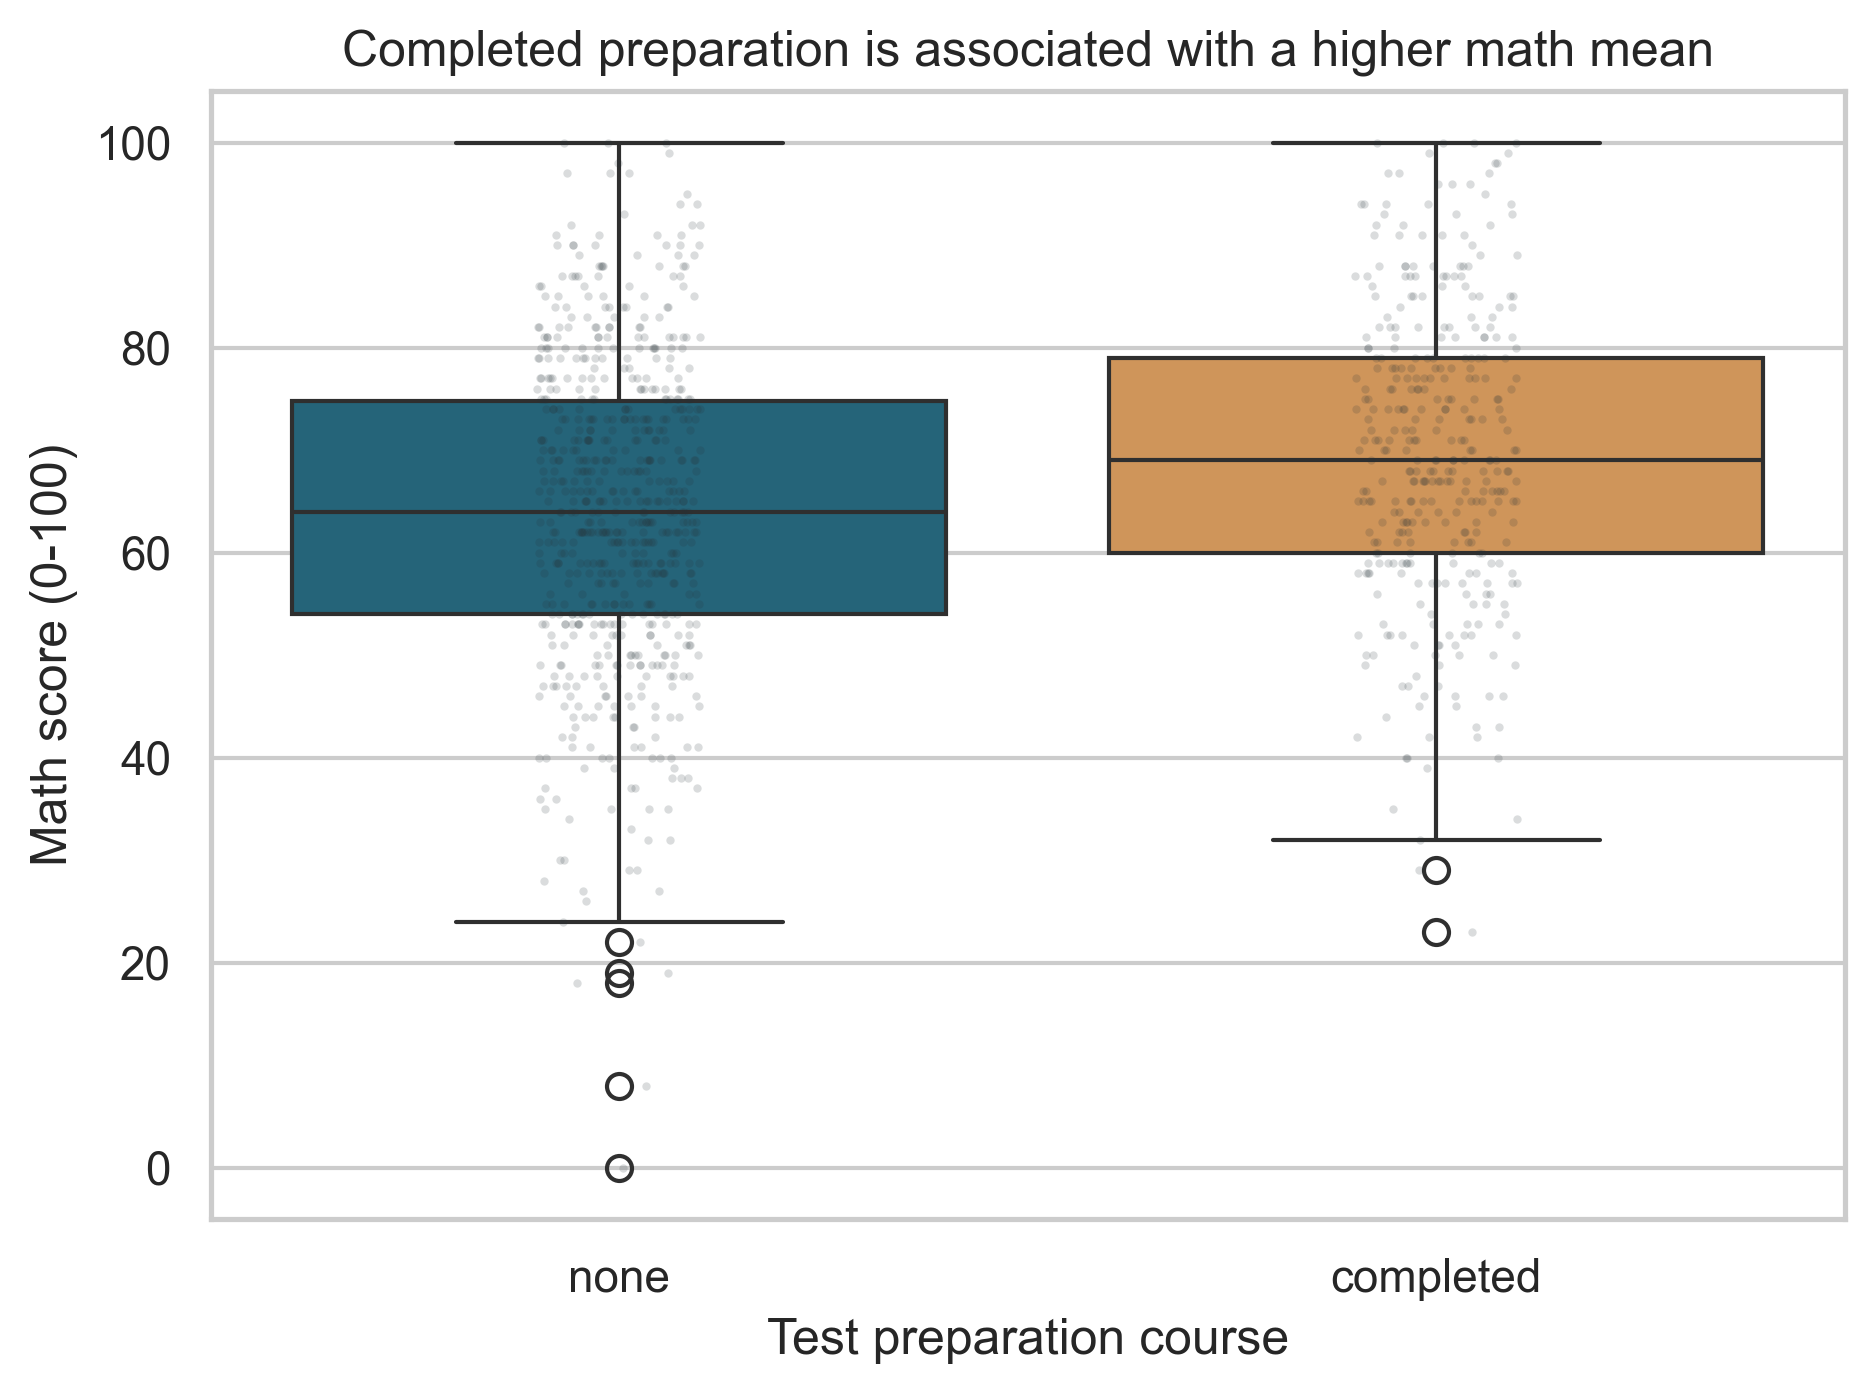

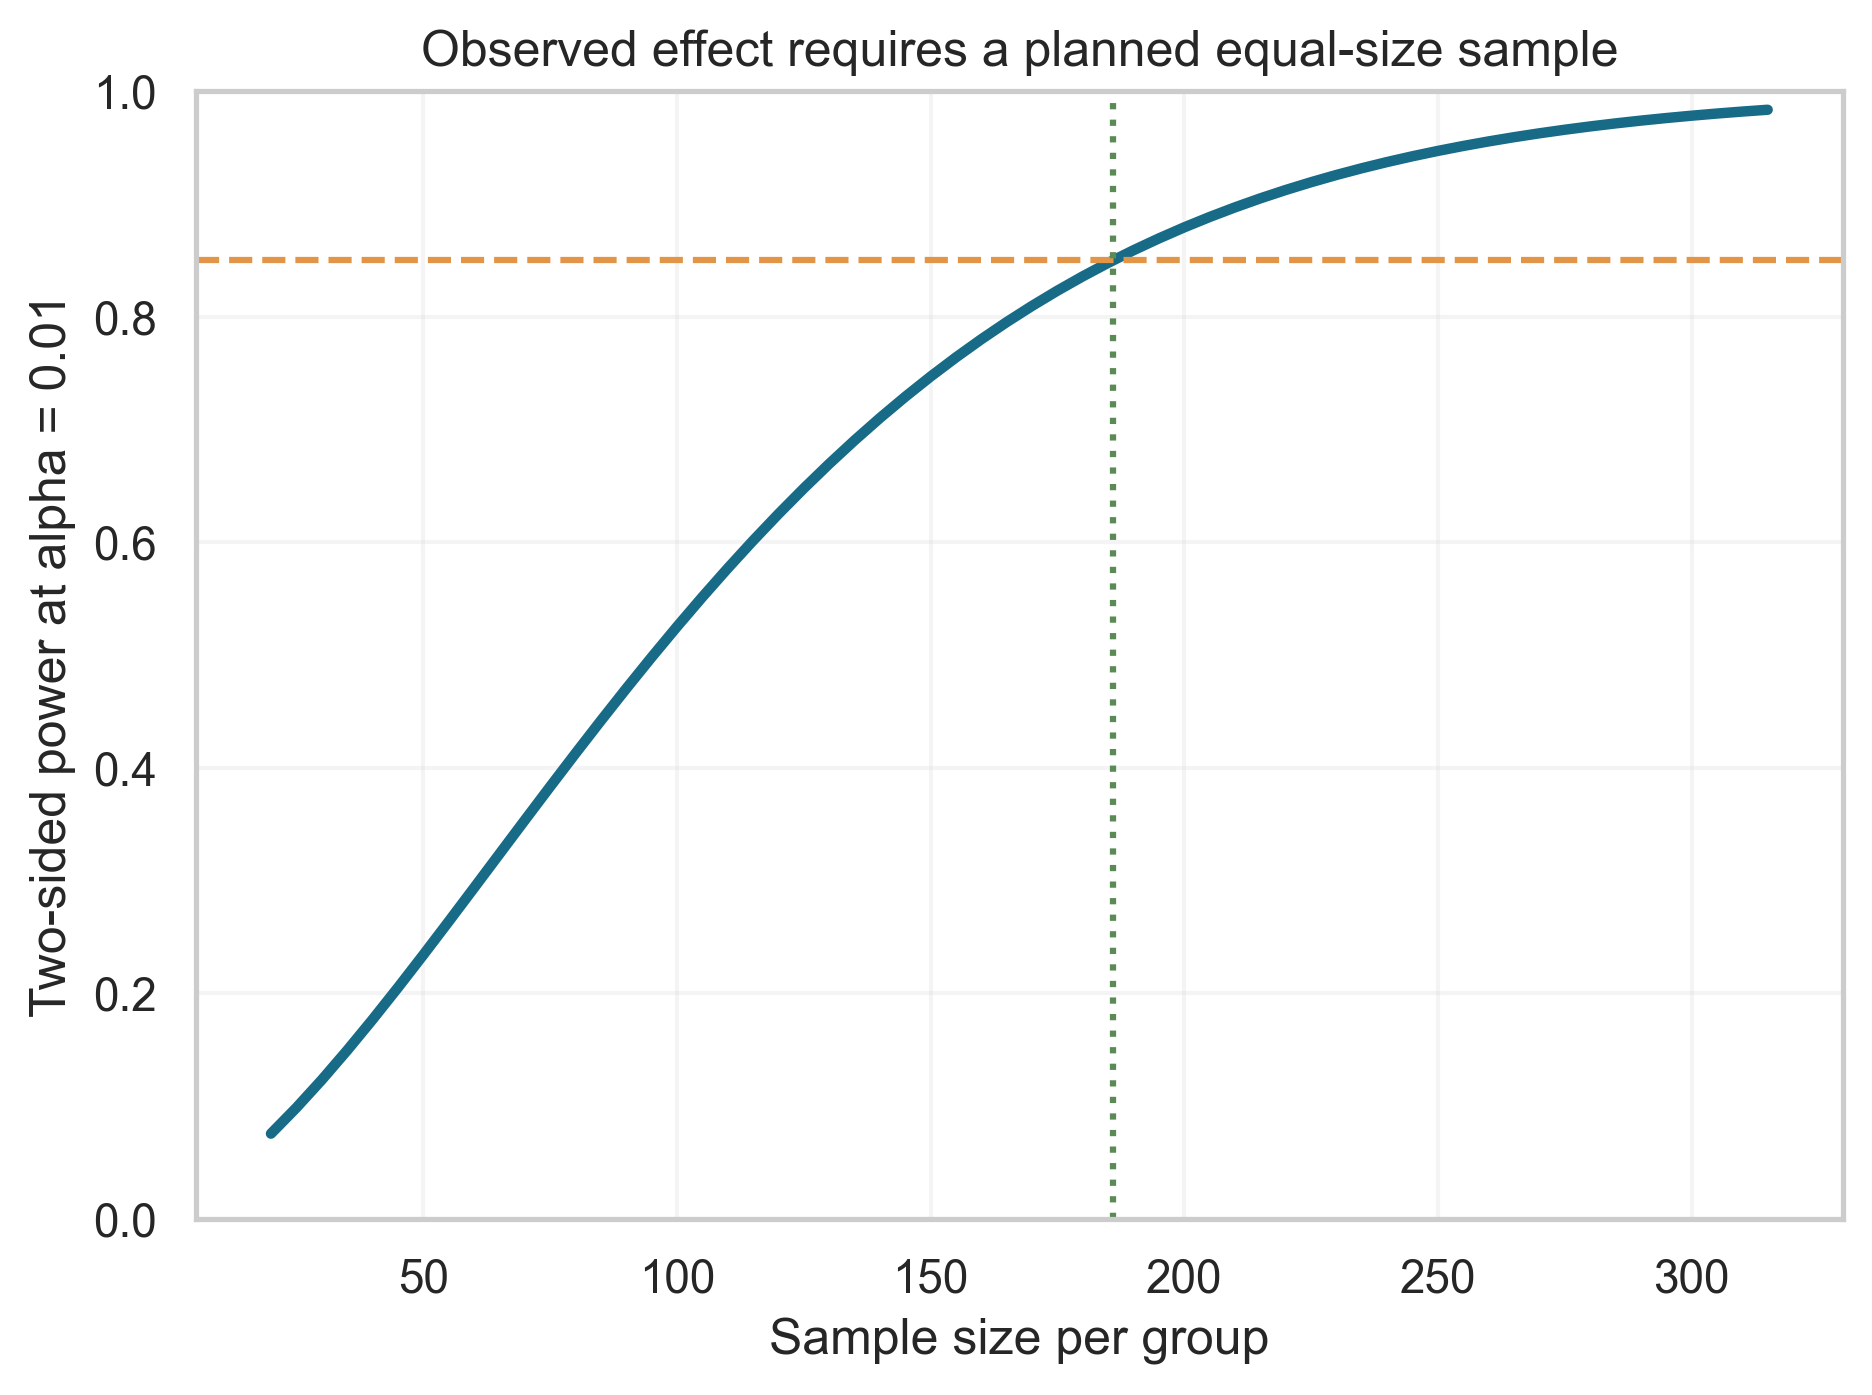

In [6]:
P = R['module4']
display(pd.DataFrame([{'Completed n':P['n_a'], 'None n':P['n_b'],
    'Completed mean':P['mean_a'], 'None mean':P['mean_b'], 'Welch t':P['statistic'],
    'df':P['df'], 'p':P['p'], 'Cohen d':P['effect'],
    '95% CI for mean difference':str([round(x,3) for x in P['ci']]),
    'Levene p':P['levene'], 'Required n/group':P['required_n_per_group']}]).round(4))
for name in ['08_math_test_prep','09_power_curve']:
    display(Image(filename=str(FIG/f'{name}.png'), width=700))

**Interpretation.** Completion is associated with a higher mean in this dataset. Participation was not randomized; prior ability, motivation, and family support can confound the difference. The dataset source acknowledges generated exam data. The observed effect size is uncertain, so the power calculation is only a planning illustration.

## 5 | Composite academic index

For each student, standardize math, reading, and writing scores using full-sample means and sample SDs, then average the three z-scores. H0: female and male index means are equal; H1: different. Welch targets this mean contrast; large groups support mean inference despite one Shapiro rejection. Pearson measures the approximately linear reading–writing relationship; Spearman is a sensitivity check.

Pearson r: 0.9546 95% CI: [np.float64(0.9488), np.float64(0.9598)]
Spearman rho: 0.949
Female-minus-male score gaps: {'math score': -5.1, 'reading score': 7.14, 'writing score': 9.16}


,Female mean,Male mean,Difference,Welch t,p,Cohen d,95% CI
0,0.1213,-0.1304,0.2517,4.2241,0.0,0.2668,"[np.float64(0.135), np.float64(0.368)]"


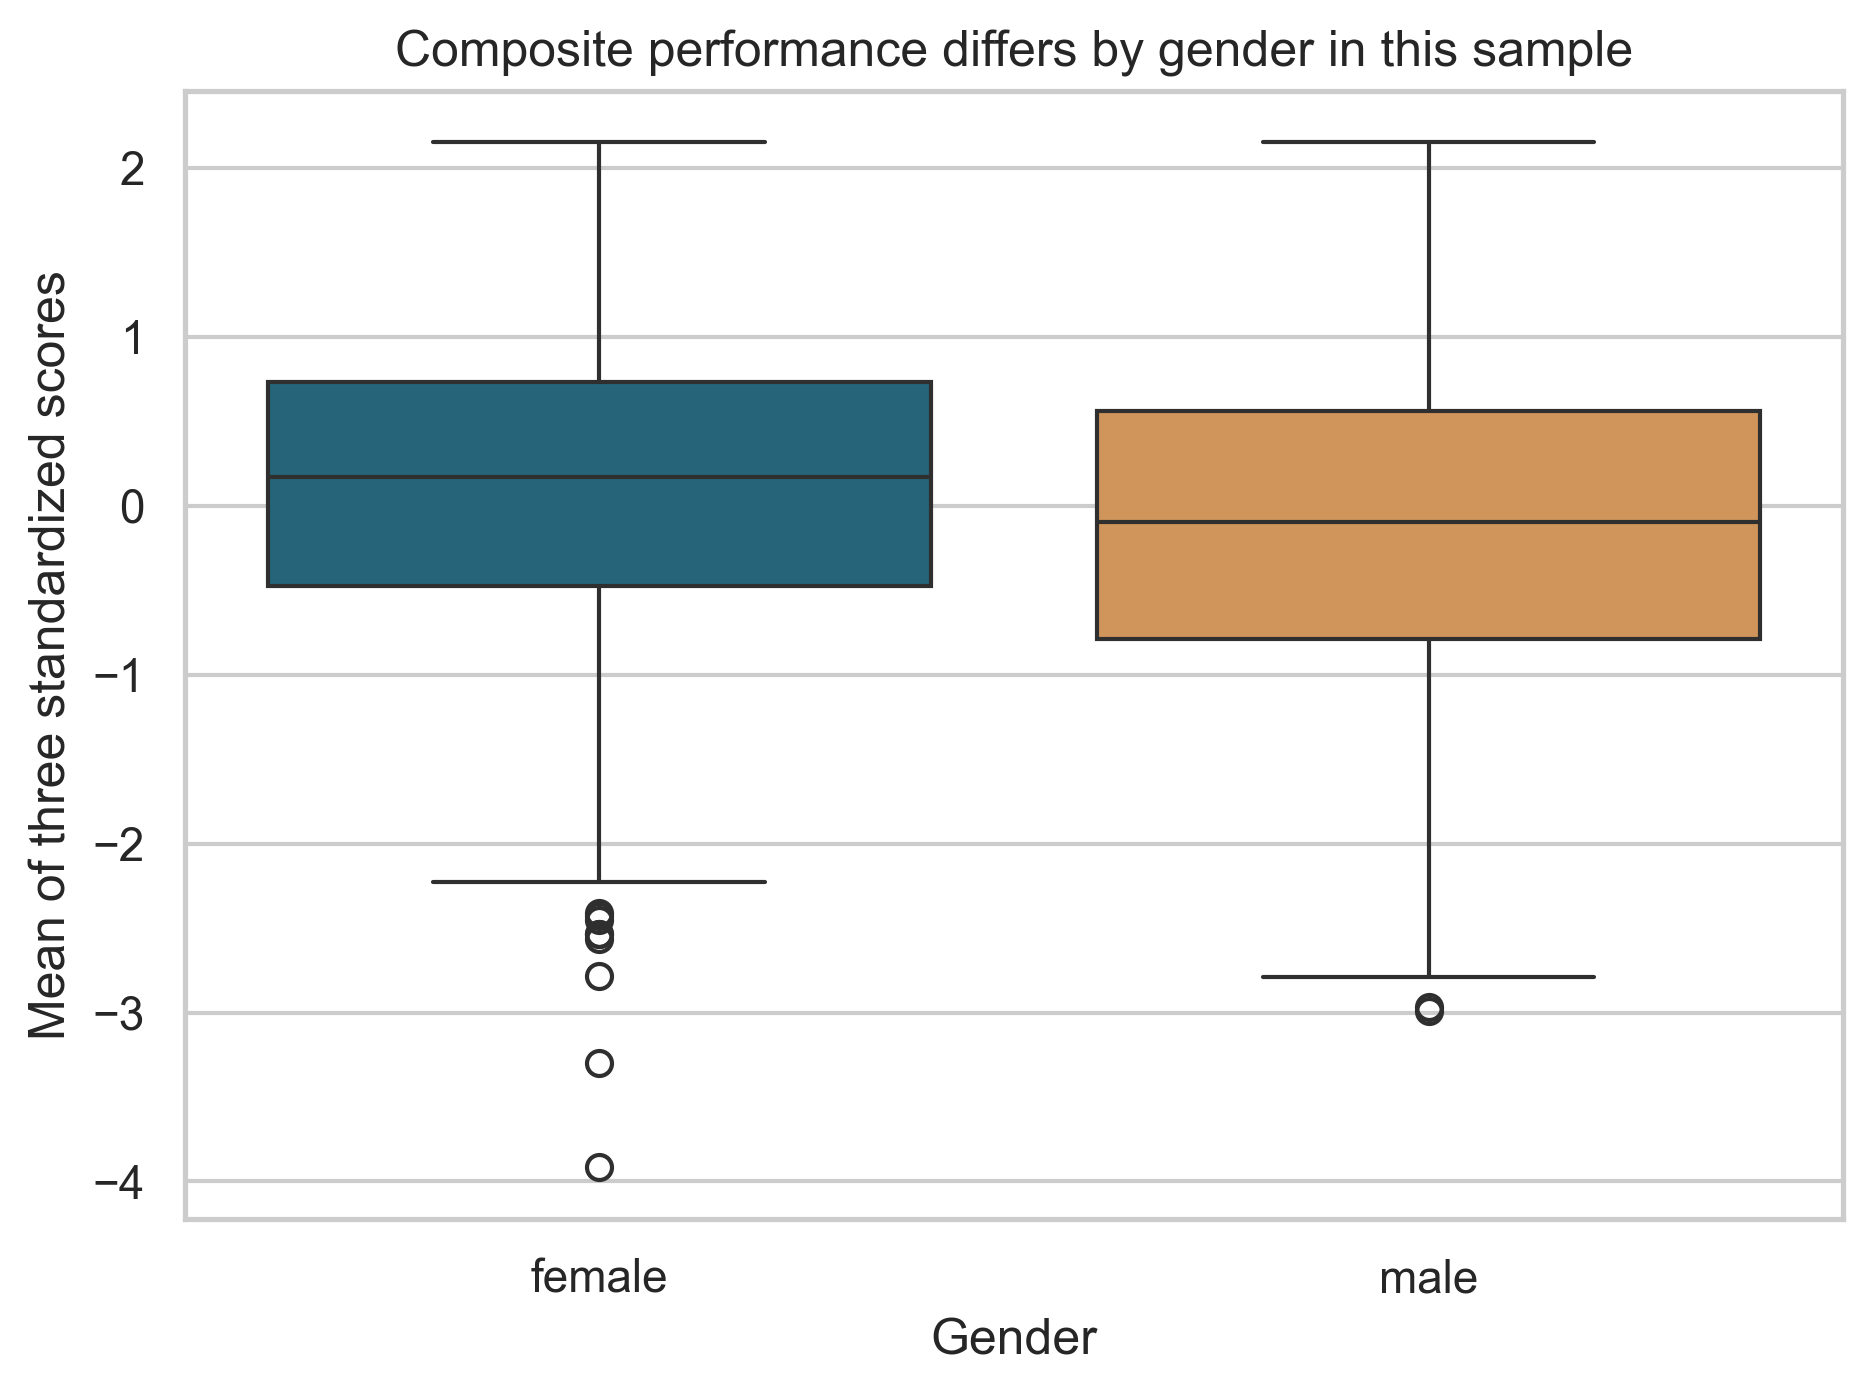

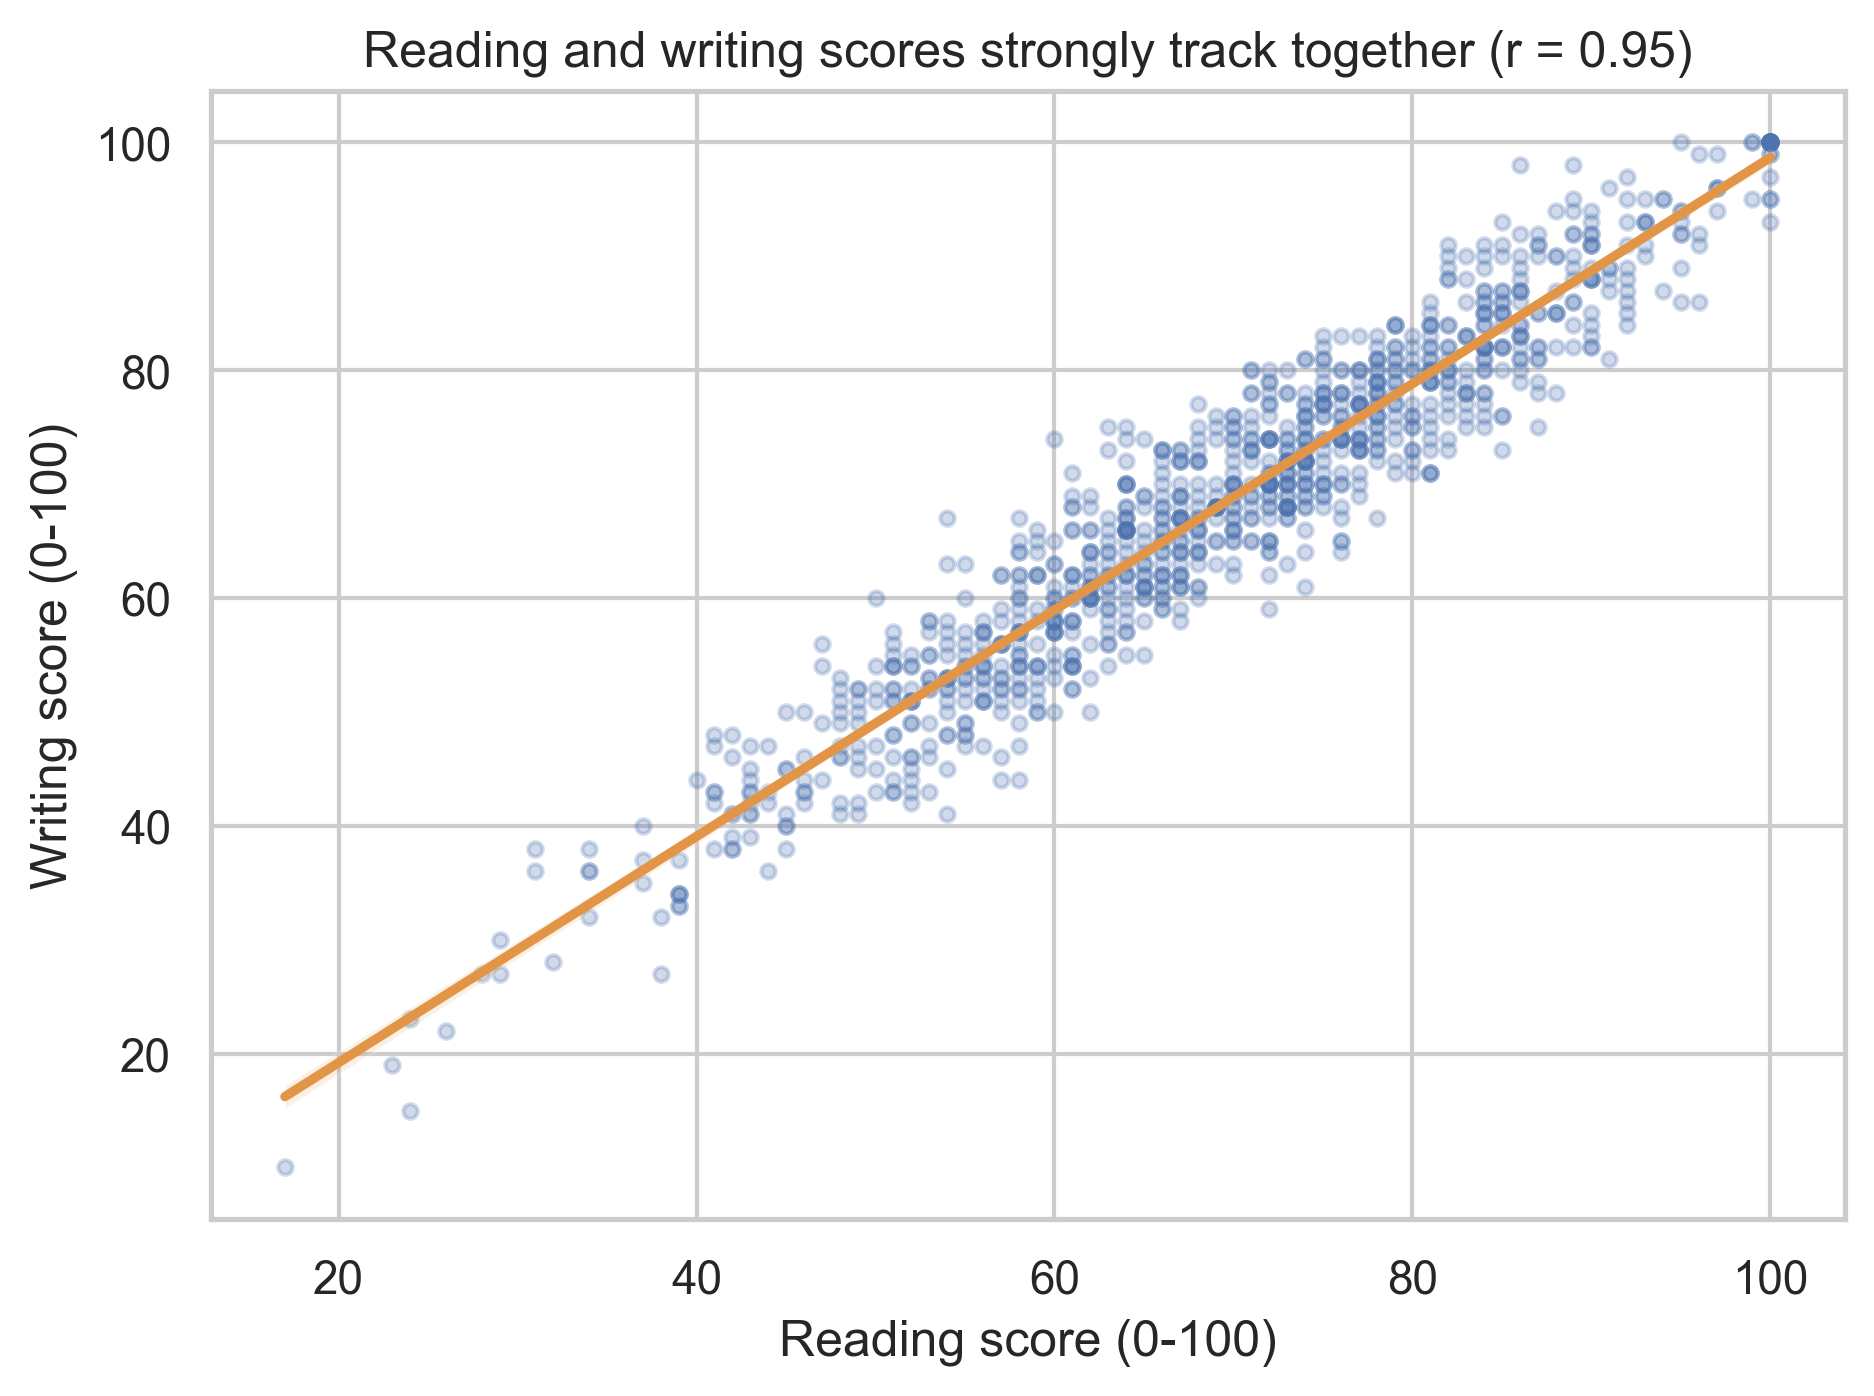

In [7]:
C = R['module5']; G = C['comparison']
display(pd.DataFrame([{'Female mean':G['mean_a'],'Male mean':G['mean_b'],
  'Difference':G['mean_a']-G['mean_b'],'Welch t':G['statistic'],'p':G['p'],
  'Cohen d':G['effect'],'95% CI':str([round(x,3) for x in G['ci']])}]).round(4))
print('Pearson r:',round(C['pearson_r'],4),'95% CI:',[round(x,4) for x in C['pearson_ci']])
print('Spearman rho:',round(C['spearman_r'],4))
print('Female-minus-male score gaps:',{k:round(v,2) for k,v in C['subject_gap_female_minus_male'].items()})
for name in ['10_composite_gender','11_reading_writing']:
    display(Image(filename=str(FIG/f'{name}.png'), width=700))

**Interpretation.** The positive female-group composite gap is driven by reading and writing despite a lower math mean. Reading and writing are highly correlated, so equal weighting partly double-counts a shared verbal-performance dimension. Alternative weighting could alter the contrast.

## Reproduce

`python -m src.run_all` regenerates JSON and figures; `python build_notebook.py` executes and saves this notebook; `python build_report.py` creates LaTeX result macros, then compile `reports/latex/main.tex` twice. These analyses describe the supplied files and assumptions, not a target population or an intervention effect.